# [New York City Taxi Trip Duration (Kaggle competition)](https://www.kaggle.com/competitions/nyc-taxi-trip-duration)

Analytics Solutions Bootcamp Case Study 5B - DS Regression Problem

---

New York City taxi operators handle a large number of trips across different locations, times of day, traffic conditions, and passenger demands. Before a trip begins, passengers and dispatch teams need a reasonable estimate of how long the journey may take.

Accurate trip-duration estimates can support:

- More reliable passenger arrival-time estimates
- Better driver and vehicle allocation
- Improved dispatch planning
- Identification of locations and periods with unusually long travel times
- Better monitoring of model reliability during congestion and unusual events

In this problem, we will build and evaluate a regression solution, and predict the duration of each trip in seconds.

In [1]:
import warnings
from pathlib import Path
from pprint import pprint

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import root_mean_squared_log_error, root_mean_squared_error
from sklearn.metrics import mean_absolute_error, median_absolute_error
from sklearn.metrics import r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import cross_validate, GridSearchCV
from sklearn.model_selection import cross_val_predict
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline, make_pipeline

from sklearn.linear_model import Ridge, GammaRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.simplefilter(action="ignore", category=FutureWarning)

SEED = 13

In [2]:
DATA_PATH = Path().cwd() / "data"

handle = "nyc-taxi-trip-duration"
dataset_dir = DATA_PATH / handle

if not dataset_dir.is_dir() or not any(dataset_dir.iterdir()):
    kagglehub.competition_download(
        handle=handle,
        output_dir=dataset_dir
    )
    print("Successfully saved files:", dataset_dir)
else:
    print("Files already exist:", dataset_dir)

Files already exist: D:\Users\Esperine\Workspace3\asb-main\cs5\data\nyc-taxi-trip-duration


## 1 - Loading and initial check

- Read the training data into a dataframe
- Check for missing (null) values
- Identify types of variable and their count

In [3]:
train_df = pd.read_csv(dataset_dir / "train.zip", compression="zip")
test_df = pd.read_csv(dataset_dir / "test.zip", compression="zip")

In [4]:
train_df.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


In [5]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1458644 non-null  str    
 1   vendor_id           1458644 non-null  int64  
 2   pickup_datetime     1458644 non-null  str    
 3   dropoff_datetime    1458644 non-null  str    
 4   passenger_count     1458644 non-null  int64  
 5   pickup_longitude    1458644 non-null  float64
 6   pickup_latitude     1458644 non-null  float64
 7   dropoff_longitude   1458644 non-null  float64
 8   dropoff_latitude    1458644 non-null  float64
 9   store_and_fwd_flag  1458644 non-null  str    
 10  trip_duration       1458644 non-null  int64  
dtypes: float64(4), int64(3), str(4)
memory usage: 189.2 MB


In [6]:
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 625134 entries, 0 to 625133
Data columns (total 9 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  625134 non-null  str    
 1   vendor_id           625134 non-null  int64  
 2   pickup_datetime     625134 non-null  str    
 3   passenger_count     625134 non-null  int64  
 4   pickup_longitude    625134 non-null  float64
 5   pickup_latitude     625134 non-null  float64
 6   dropoff_longitude   625134 non-null  float64
 7   dropoff_latitude    625134 non-null  float64
 8   store_and_fwd_flag  625134 non-null  str    
dtypes: float64(4), int64(2), str(3)
memory usage: 60.2 MB


In [7]:
# Fix datetime formatting
train_df["pickup_datetime"] = pd.to_datetime(train_df["pickup_datetime"], errors="coerce")
train_df["dropoff_datetime"] = pd.to_datetime(train_df["dropoff_datetime"], errors="coerce")
test_df["pickup_datetime"] = pd.to_datetime(test_df["pickup_datetime"], errors="coerce")

In [8]:
train_df.nunique()

id                    1458644
vendor_id                   2
pickup_datetime       1380222
dropoff_datetime      1380377
passenger_count            10
pickup_longitude        23047
pickup_latitude         45245
dropoff_longitude       33821
dropoff_latitude        62519
store_and_fwd_flag          2
trip_duration            7417
dtype: int64

In [9]:
train_df.describe().transpose()

,count,mean,min,25%,50%,75%,max,std
vendor_id,1458644.0,1.53495,1.0,1.0,2.0,2.0,2.0,0.498777
pickup_datetime,1458644,2016-04-01 10:10:24.940038,2016-01-01 00:00:17,2016-02-17 16:46:04.250000,2016-04-01 17:19:40,2016-05-15 03:56:08.750000,2016-06-30 23:59:39,NaN
dropoff_datetime,1458644,2016-04-01 10:26:24.432309,2016-01-01 00:03:31,2016-02-17 17:05:32.500000,2016-04-01 17:35:12,2016-05-15 04:10:51.750000,2016-07-01 23:02:03,NaN
passenger_count,1458644.0,1.66453,0.0,1.0,1.0,2.0,9.0,1.314242
pickup_longitude,1458644.0,-73.973486,-121.933342,-73.991867,-73.981743,-73.967331,-61.335529,0.070902
pickup_latitude,1458644.0,40.750921,34.359695,40.737347,40.754101,40.76836,51.881084,0.032881
dropoff_longitude,1458644.0,-73.973416,-121.933304,-73.991325,-73.979752,-73.963013,-61.335529,0.070643
dropoff_latitude,1458644.0,40.7518,32.181141,40.735885,40.754524,40.76981,43.921028,0.035891
trip_duration,1458644.0,959.492273,1.0,397.0,662.0,1075.0,3526282.0,5237.431724


By looking at the summary statistics, the training data contains anomalous records. We would filter them later on during quality checks.

In [10]:
# Taking a closer look at trip duration
train_df["trip_duration"].describe(percentiles=[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]).round(2)

count    1458644.00
mean         959.49
std         5237.43
min            1.00
10%          245.00
20%          348.00
30%          446.00
40%          548.00
50%          662.00
60%          798.00
70%          968.00
80%         1208.00
90%         1634.00
max      3526282.00
Name: trip_duration, dtype: float64

In [11]:
train_df["trip_duration"].quantile((0.005, 0.995))

0.005      50.0
0.995    4139.0
Name: trip_duration, dtype: float64

In [12]:
# Taking a closer look at passenger count
train_df["passenger_count"].value_counts()

passenger_count
1    1033540
2     210318
5      78088
3      59896
6      48333
4      28404
0         60
7          3
9          1
8          1
Name: count, dtype: int64

## 2 - Data quality assessment, boundary checks, and filtering

The training data collected from physical IoT sensors (taximeters, GPS chipsets) contain physical anomalies, corrupted logs, and transmission artifacts. We need to check the quality of the training data, perform checks, and filter records with anomaly.

**Coordinate Bounding Box Filtering**

GPS sensors occasionally default to `(0.0, 0.0)` or record spurious coordinates far outside New York State. We define the operational geographic envelope.

- Latitude: Must be within the interval - $[40.50^\circ\text{N}, 41.00^\circ\text{N}]$
- Longitude: Must be within the interval - $[-74.25^\circ\text{W}, -73.70^\circ\text{W}]$

**Target Boundary Rules**

- Lower Bound: Trips with `trip_duration` <60 seconds indicate immediate driver cancellation or meter misclicks.
- Upper Bound: Trips with `trip_duration` >7200 seconds (or 2 hours) reflect unclosed meters or hardware faults.

**Speed Audit**

We calculate approximate straight-line displacement or the haversine distance ($D_{\text{hav}}$). If $D_{\text{hav}} > 0.5\text{ km}$ and the implied speed below, the record represents erroneous coordinates or corrupted timestamps.

$$ v_{\text{implied}} = \frac{D_{\text{harv}}}{\text{trip\_duration}} > 45\text{ m/s } (\approx 162\text{ km/h / } 100\text{ mph}) $$

**Others**

Filter other anomalies such as zero passenger count.

In [13]:
# ==============================================================================
# STRUCTURAL AUDIT: SCHEMA, MISSINGNESS, AND DUPLICATES
# ==============================================================================

def run_structural_audit(train_df: pd.DataFrame, test_df: pd.DataFrame) -> dict:
    """
    Performs baseline inventory and checks for column parity, missing values,
    and ID uniqueness between train and test sets.
    """
    audit_report = {
        "train_shape": train_df.shape,
        "test_shape": test_df.shape,
        "train_missing": train_df.isnull().sum().to_dict(),
        "test_missing": test_df.isnull().sum().to_dict(),
        "train_duplicate_ids": train_df["id"].duplicated().sum(),
        "test_duplicate_ids": test_df["id"].duplicated().sum(),
    }
    
    return audit_report


# ==============================================================================
# VECTORIZED DISTANCE & SPEED AUDIT HELPERS
# ==============================================================================

def compute_haversine_km(lat1, lon1, lat2, lon2):
    """
    Vectorized Haversine distance calculation in kilometers.
    """
    EARTH_RADIUS = 6371.0
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)
    
    a = (np.sin(dphi / 2.0) ** 2 + 
         np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2.0) ** 2)
    return 2.0 * EARTH_RADIUS * np.arcsin(np.sqrt(a))


# ==============================================================================
# TRAINING DATA FILTERING & DATA QUALITY ENFORCEMENT
# ==============================================================================

def clean_training_data(
    df: pd.DataFrame,
    min_duration_sec: int = 60,
    max_duration_sec: int = 7200,
    max_speed_kmh: float = 160.0,
    lat_bounds: tuple = (40.5, 41.0),
    lon_bounds: tuple = (-74.25, -73.70)
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Evaluates physical, spatial, and temporal plausibility rules on train.csv.
    Generates a diagnostic audit log showing records dropped per rule.
    """
    initial_count = len(df)
    clean_df = df.copy()
    
    # Compute displacement and implied speed for the audit
    clean_df["haversine_dist_km"] = compute_haversine_km(
        clean_df["pickup_latitude"], clean_df["pickup_longitude"],
        clean_df["dropoff_latitude"], clean_df["dropoff_longitude"]
    )
    # Implied speed in km/h: (km / seconds) * 3600
    clean_df["implied_speed_kmh"] = (
        clean_df["haversine_dist_km"] / np.maximum(clean_df["trip_duration"], 1)
    ) * 3600.0

    # Define validation Boolean masks
    masks = {
        # Target bounds: positive duration, >10s (aborts), <24h (stuck meters)
        "invalid_duration": (
            (clean_df["trip_duration"] < min_duration_sec) | 
            (clean_df["trip_duration"] > max_duration_sec)
        ),
        # Coordinate bounds: strictly within the NYC metropolitan operational box
        "outside_spatial_box": (
            ~clean_df["pickup_latitude"].between(*lat_bounds) |
            ~clean_df["dropoff_latitude"].between(*lat_bounds) |
            ~clean_df["pickup_longitude"].between(*lon_bounds) |
            ~clean_df["dropoff_longitude"].between(*lon_bounds)
        ),
        # Passenger count bounds: 0 passengers or >6 (NYC taxi regulatory vehicle capacity)
        "implausible_passenger_count": (
            (clean_df["passenger_count"] < 1) | 
            (clean_df["passenger_count"] > 6)
        ),
        # Kinematic impossibility: distance > 500m but implied speed exceeding highway limit
        "impossible_speed": (
            (clean_df["haversine_dist_km"] > 0.5) & 
            (clean_df["implied_speed_kmh"] > max_speed_kmh)
        ),
        # Zero-displacement trip lasting longer than 5 minutes (meter kept running without motion)
        "stationary_long_trip": (
            (clean_df["haversine_dist_km"] == 0.0) & 
            (clean_df["trip_duration"] > 300)
        )
    }

    # Compile audit summary
    audit_records = []
    combined_mask = pd.Series(False, index=clean_df.index)

    for rule_name, mask in masks.items():
        violations = mask.sum()
        pct = (violations / initial_count) * 100.0
        audit_records.append({
            "Criterion": rule_name,
            "Violations": violations,
            "Percentage": f"{pct:.3f}%"
        })
        combined_mask = combined_mask | mask

    audit_summary_df = pd.DataFrame(audit_records)
    
    # Filter the dataset and clean up intermediate diagnostic columns
    clean_df = clean_df[~combined_mask].reset_index(drop=True)
    clean_df = clean_df.drop(columns=["haversine_dist_km", "implied_speed_kmh"])
    
    total_dropped = initial_count - len(clean_df)
    total_pct = (total_dropped / initial_count) * 100.0
    
    print(f"Data cleaning completed: {total_dropped:,} rows dropped ({total_pct:.2f}% of total).")
    print(f"Final usable training records: {len(clean_df):,}")
    
    return clean_df, audit_summary_df

In [14]:
# Perform structural audit
structural_results = run_structural_audit(train_df, test_df)

print("--- Structural Audit Summary ---")
print(f"Train shape: {structural_results["train_shape"]} | Test shape: {structural_results["test_shape"]}")
print(f"Train duplicate IDs: {structural_results["train_duplicate_ids"]} | Test duplicate IDs: {structural_results["test_duplicate_ids"]}")

--- Structural Audit Summary ---
Train shape: (1458644, 11) | Test shape: (625134, 9)
Train duplicate IDs: 0 | Test duplicate IDs: 0


In [15]:
# Apply domain bounds and filtering
df, audit_log = clean_training_data(train_df)

print("\n--- Rule Violation Breakdown ---")
print(audit_log.to_string(index=False))

Data cleaning completed: 14,916 rows dropped (1.02% of total).
Final usable training records: 1,443,728

--- Rule Violation Breakdown ---
                  Criterion  Violations Percentage
           invalid_duration       10848     0.744%
        outside_spatial_box        1027     0.070%
implausible_passenger_count          65     0.004%
           impossible_speed          57     0.004%
       stationary_long_trip        3191     0.219%


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1443728 entries, 0 to 1443727
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   id                  1443728 non-null  str           
 1   vendor_id           1443728 non-null  int64         
 2   pickup_datetime     1443728 non-null  datetime64[us]
 3   dropoff_datetime    1443728 non-null  datetime64[us]
 4   passenger_count     1443728 non-null  int64         
 5   pickup_longitude    1443728 non-null  float64       
 6   pickup_latitude     1443728 non-null  float64       
 7   dropoff_longitude   1443728 non-null  float64       
 8   dropoff_latitude    1443728 non-null  float64       
 9   store_and_fwd_flag  1443728 non-null  str           
 10  trip_duration       1443728 non-null  int64         
dtypes: datetime64[us](2), float64(4), int64(3), str(2)
memory usage: 135.3 MB


In [17]:
df["trip_duration"].describe().transpose().round(2)

count    1443728.00
mean         839.95
std          651.76
min           60.00
25%          401.00
50%          665.00
75%         1075.00
max         7191.00
Name: trip_duration, dtype: float64

## 3 - Exploratory data analysis

### 3.1 - Trip duration

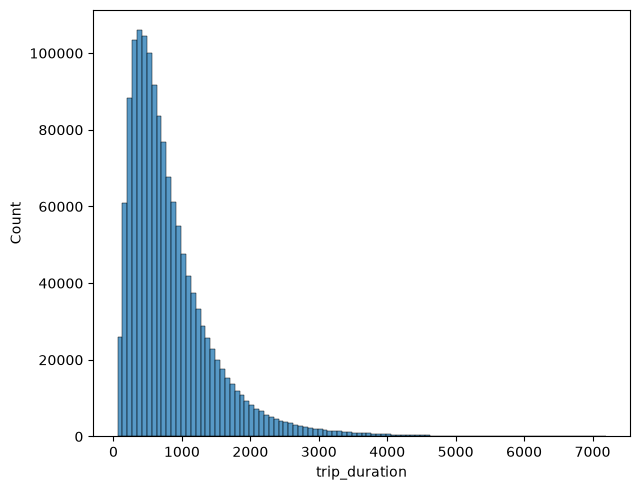

In [18]:
# Consider the distribution of trip duration

fig, ax = plt.subplots(figsize=(6.5, 5))

sns.histplot(df["trip_duration"], bins=100, ax=ax)

fig.tight_layout()

We expect that most trip durations would be short, thus the distribution is positively skewed. Let's consider applying a logarithmic transformation to scale the values.

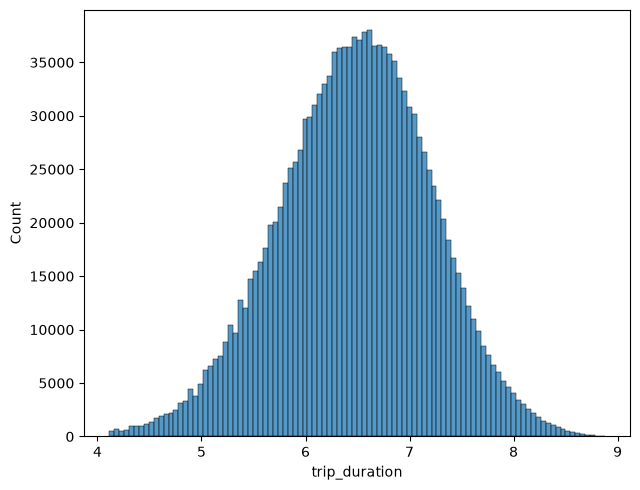

In [19]:
# Trip duration in logarithmic scale

fig, ax = plt.subplots(figsize=(6.5, 5))

sns.histplot(np.log1p(df["trip_duration"]), bins=100, ax=ax)

fig.tight_layout()

### 3.2 - Categorical variables

#### 3.2.1 - Vendor ID

vendor_id
2    53.0
1    47.0
Name: proportion, dtype: float64

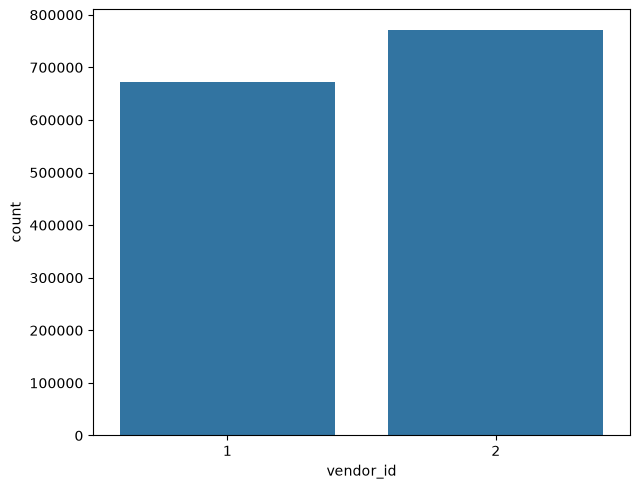

In [20]:
# Trip count by vendor ID

fig, ax = plt.subplots(figsize=(6.5, 5))

sns.countplot(data=df, x="vendor_id", ax=ax)

fig.tight_layout()

df["vendor_id"].value_counts(normalize=True).round(2) * 100

#### 3.2.2 - Passenger count

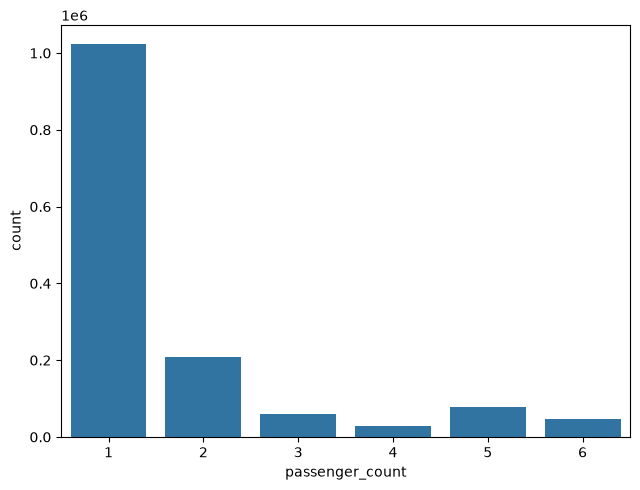

In [21]:
# Trip count by number of passenger

fig, ax = plt.subplots(figsize=(6.5, 5))

sns.countplot(data=df, x="passenger_count", ax=ax)

fig.tight_layout()

#### 3.2.3 - Store and forward flag

store_and_fwd_flag
N    99.45
Y     0.55
Name: proportion, dtype: float64

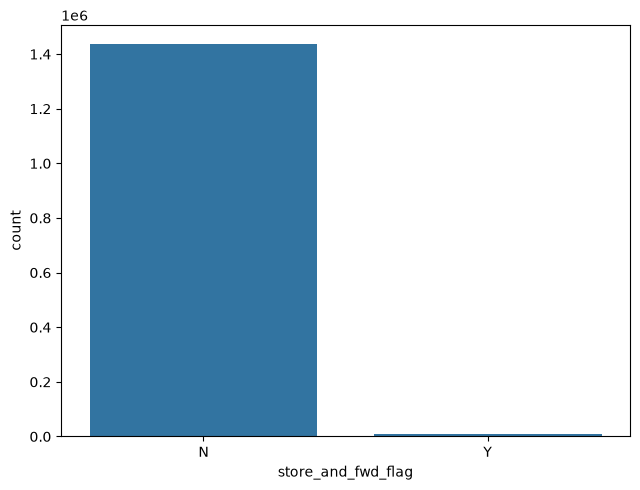

In [22]:
# Trip count by store and forward flag

fig, ax = plt.subplots(figsize=(6.5, 5))

sns.countplot(data=df, x="store_and_fwd_flag", ax=ax)

fig.tight_layout()

(df["store_and_fwd_flag"].value_counts(normalize=True) * 100).round(2)

#### 3.3.4 - Takeaways

- The categorical variables show expected operational patterns within the NYC taxi system.
- Vendor distribution appears relatively balanced, reducing the likelihood of vendor-specific sampling bias.
- Passenger counts are concentrated around one or two passengers, indicating that most taxi trips involve individual travelers or small groups.
- The store-and-forward flag is dominated by one category, suggesting that delayed transmission events are relatively uncommon and may have limited predictive value.

### 3.3 - Trip patterns through time

Let's understand how trip patterns vary by hour of day, day of week, month, and weekday vs. weekend.

In [23]:
time_df = df[["id", "trip_duration"]]

time_df["pickup_hour"] = df["pickup_datetime"].dt.hour
time_df["pickup_day"] = df["pickup_datetime"].dt.day
time_df["pickup_month"] = df["pickup_datetime"].dt.month
time_df["pickup_day_name"] = df["pickup_datetime"].dt.day_name()
time_df["pickup_month_name"] = df["pickup_datetime"].dt.month_name()
time_df["is_weekend"] = df["pickup_datetime"].dt.day_of_week >= 5

time_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1443728 entries, 0 to 1443727
Data columns (total 8 columns):
 #   Column             Non-Null Count    Dtype
---  ------             --------------    -----
 0   id                 1443728 non-null  str  
 1   trip_duration      1443728 non-null  int64
 2   pickup_hour        1443728 non-null  int32
 3   pickup_day         1443728 non-null  int32
 4   pickup_month       1443728 non-null  int32
 5   pickup_day_name    1443728 non-null  str  
 6   pickup_month_name  1443728 non-null  str  
 7   is_weekend         1443728 non-null  bool 
dtypes: bool(1), int32(3), int64(1), str(3)
memory usage: 92.0 MB


#### 3.3.1 - Trip distribution by hour

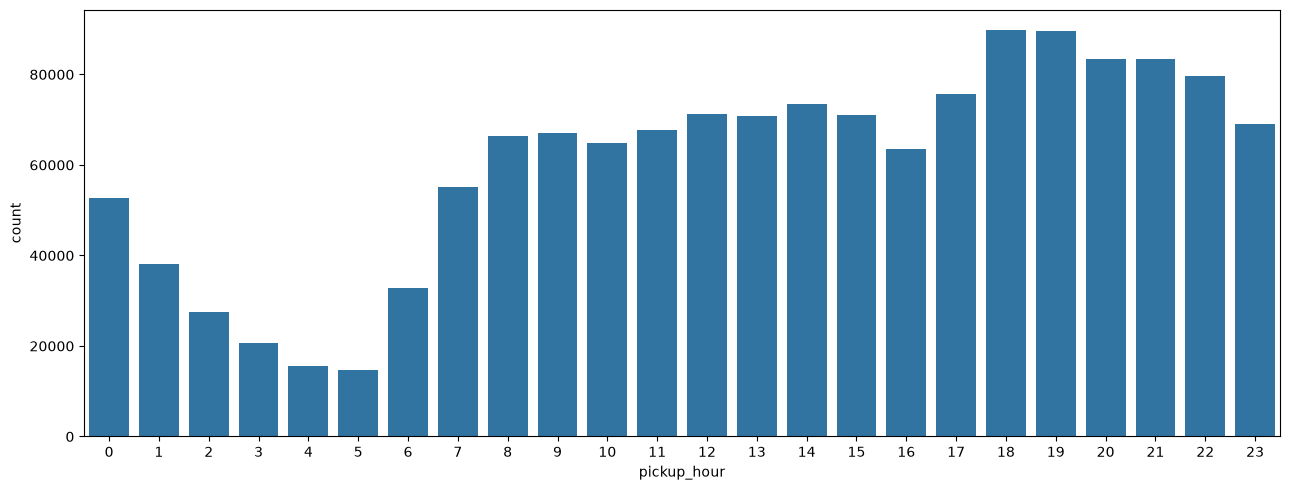

In [24]:
fig, ax = plt.subplots(figsize=(13, 5))

sns.countplot(data=time_df, x="pickup_hour", ax=ax)

fig.tight_layout()

#### 3.3.2 - Average duration by hour

In [25]:
hourly_duration = time_df.groupby("pickup_hour")["trip_duration"].mean().reset_index()
hourly_duration

,pickup_hour,trip_duration
0,0,784.424300
1,1,742.777877
2,2,705.224296
3,3,707.334516
4,4,741.969656
5,5,719.596853
6,6,675.293225
7,7,761.212213
8,8,837.160212
9,9,846.591300


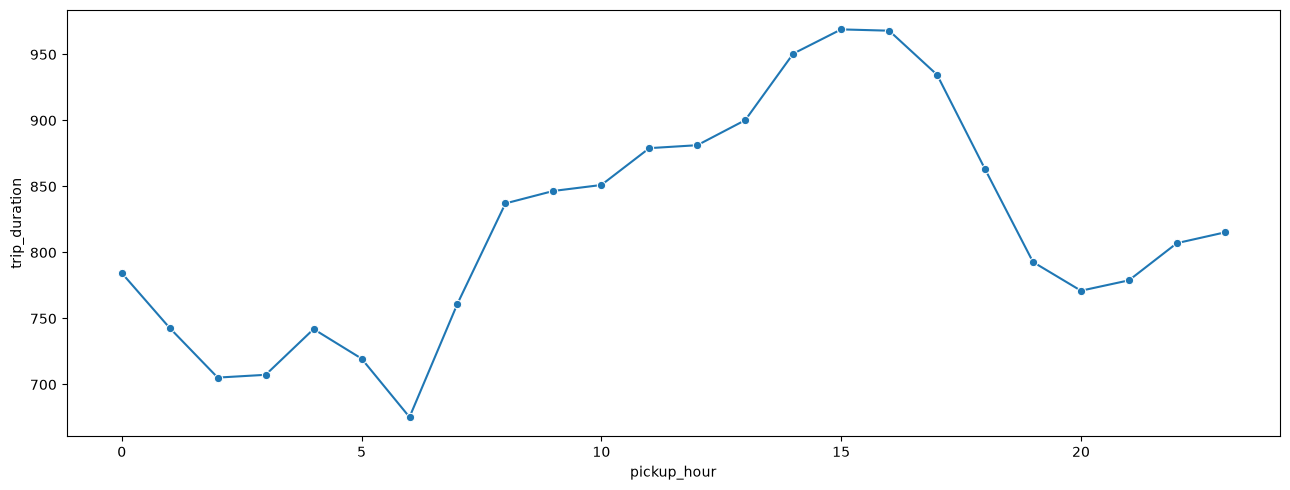

In [26]:
fig, ax = plt.subplots(figsize=(13, 5))

sns.lineplot(
    data=hourly_duration,
    x="pickup_hour",
    y="trip_duration",
    marker="o",
    ax=ax
)

fig.tight_layout()

Remarks:

- Trip activity exhibits clear diurnal patterns, with demand increasing sharply during morning and evening commuting periods.
- Average trip duration is lowest during early morning hours when traffic congestion is minimal and increases noticeably during peak commuting periods.
- These findings indicate that `pickup_hour` captures both demand fluctuations and traffic conditions, making it a potentially important predictor of trip duration.

#### 3.3.3 - Trips by day of week and weekday vs. weekend

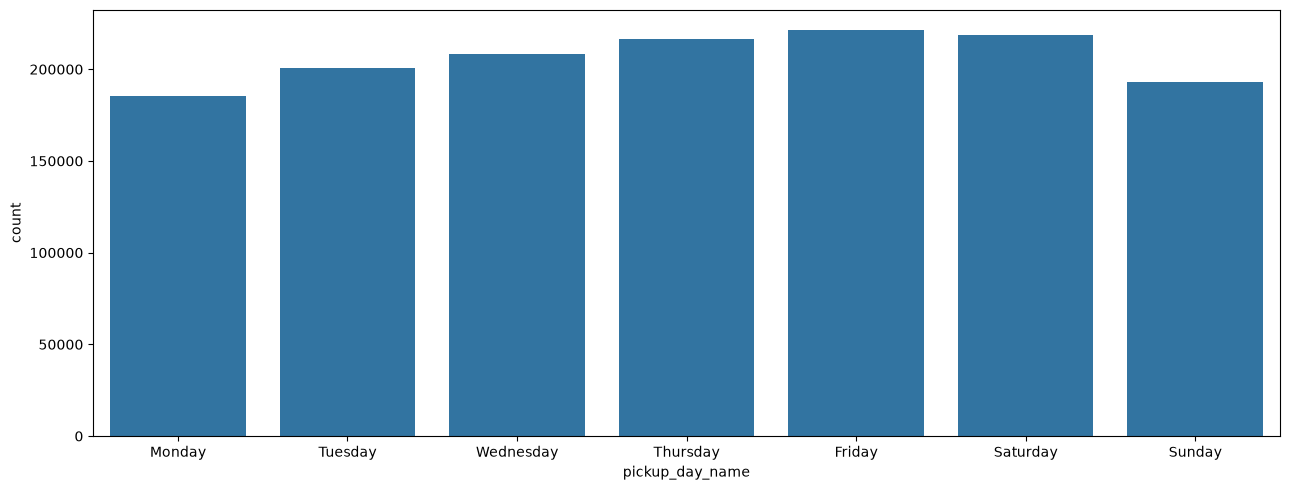

In [27]:
# Consider trip counts by day of week

day_of_week = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, ax = plt.subplots(figsize=(13, 5))

sns.countplot(
    data=time_df,
    x="pickup_day_name",
    order=day_of_week,
    ax=ax
)

fig.tight_layout()

Remarks:

- Trip demand is higher during weekdays, particularly toward the end of the work week.
- Average trip durations are generally longer on weekdays than weekends, suggesting the influence of commuter traffic and congestion.
- The `pickup_day_name` feature appears likely to contribute predictive information regarding both travel demand and traffic patterns.

#### 3.3.4 - Weekday vs. weekend

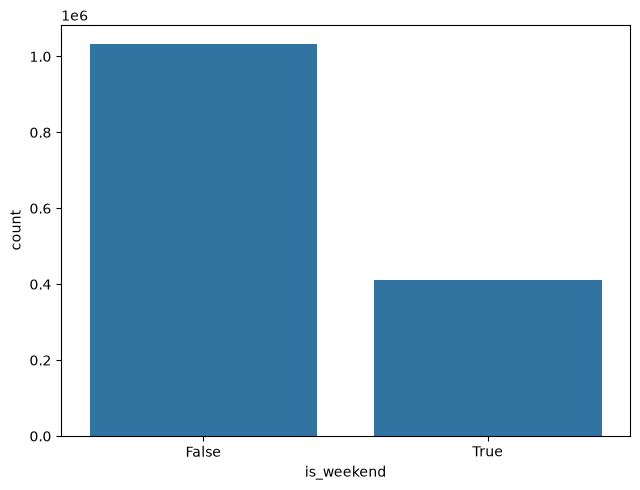

In [28]:
# Trip counts during weekdays and weekends

fig, ax = plt.subplots(figsize=(6.5, 5))

sns.countplot(
    data=time_df,
    x="is_weekend",
    ax=ax
)

fig.tight_layout()

In [29]:
# Considering average duration during weekdays and weekends in hours

time_df.groupby("is_weekend")["trip_duration"].mean().round(2) / 360

is_weekend
False    2.406250
True     2.150167
Name: trip_duration, dtype: float64

Remarks:

- There are indeed more trips during weekdays than weekends, which can be also observed when we check number of trips by day of week.
- Average trip duration is higher on weekdays than weekends, indicating that weekday traffic conditions may contribute to longer travel times.
- The `is_weekend` feature captures meaningful operational differences and should be retained for modeling.

#### 3.3.5 - Trip distribution by month

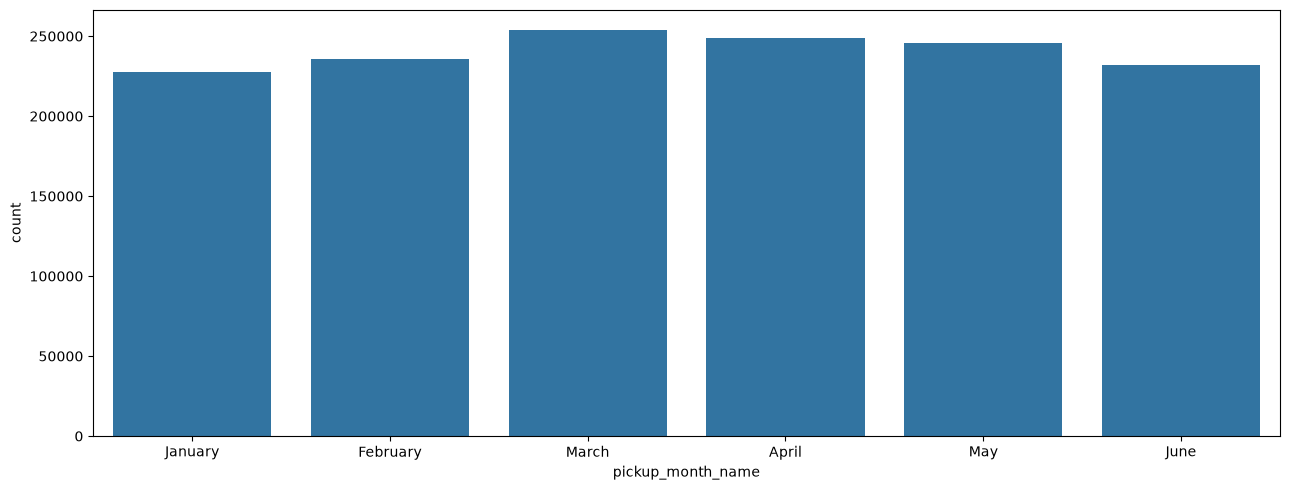

In [30]:
month_order = [
    "January", "February", "March", 
    "April", "May", "June", 
    "July", "August", "September", 
    "October", "November", "December"
]
present_month_order = [month_order[m-1] for m in sorted(time_df["pickup_month"].unique())]

fig, ax = plt.subplots(figsize=(13, 5))

sns.countplot(
    data=time_df,
    x="pickup_month_name",
    order=present_month_order,
    ax=ax
)

fig.tight_layout()

#### 3.3.6 - Average duration by month

In [31]:
monthly_duration = time_df.groupby(["pickup_month", "pickup_month_name"])["trip_duration"].mean().reset_index()
monthly_duration

,pickup_month,pickup_month_name,trip_duration
0,1,January,793.396154
1,2,February,792.750722
2,3,March,820.552580
3,4,April,851.371813
4,5,May,886.203607
5,6,June,893.559372


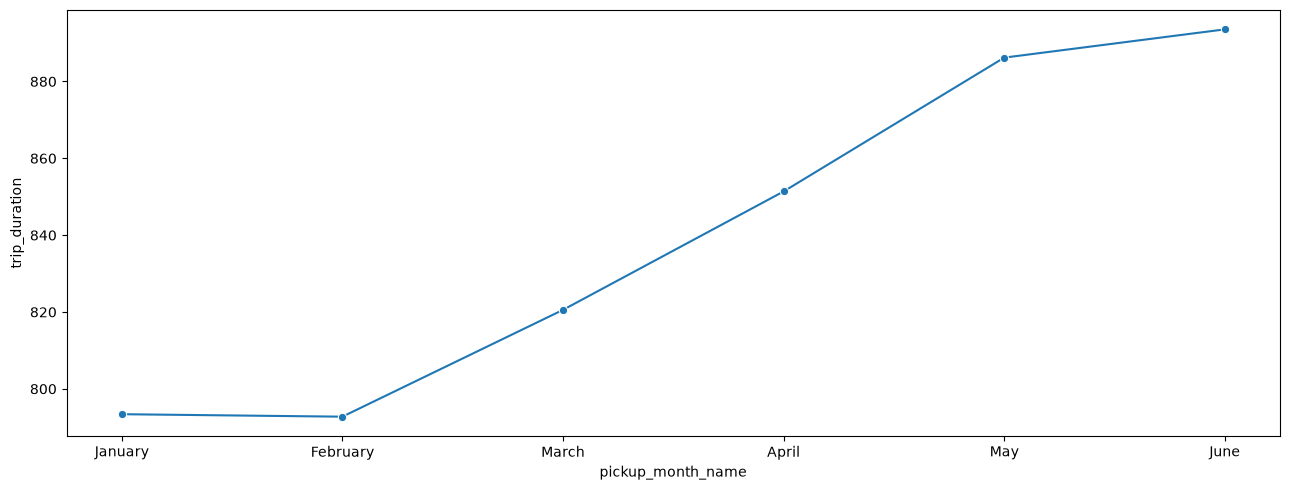

In [32]:
fig, ax = plt.subplots(figsize=(13, 5))

sns.lineplot(
    data=monthly_duration,
    x="pickup_month_name",
    y="trip_duration",
    marker="o",
    ax=ax
)

fig.tight_layout()

Remarks:

- Average trip duration shows a gradual increase from January through June.
- This pattern may reflect seasonal variations in travel demand, traffic conditions, weather, or tourism activity.
- The `pickup_month` feature may therefore provide useful contextual information for duration prediction.

#### 3.3.6 - Takeaways

Temporal features provide significant insights into taxi trip patterns and duration.

1. Hourly patterns: Both trip frequency and average duration exhibit strong hourly variations, with peaks during morning and evening rush hours and shorter durations in the early morning, indicating the direct influence of congestion.
2. Day-of-week patterns: Weekdays consistently show higher trip counts and longer average durations compared to weekends, reflecting distinct commuting behaviors and traffic conditions.
3. Monthly trends: A clear increasing trend in average trip duration from January to June suggests seasonal influences, likely due to improving weather and increased activity or tourism.

These distinct temporal variations highlight that `pickup_hour`, `pickup_day_name`, and `pickup_month` are crucial features for accurately predicting trip duration, as they capture significant demand and congestion dynamics.

### 3.4 - Geographic analysis

Let's visualize the trips by location to get a better understanding.

#### 3.4.1 - Coordinate distribution of pickups and dropoffs

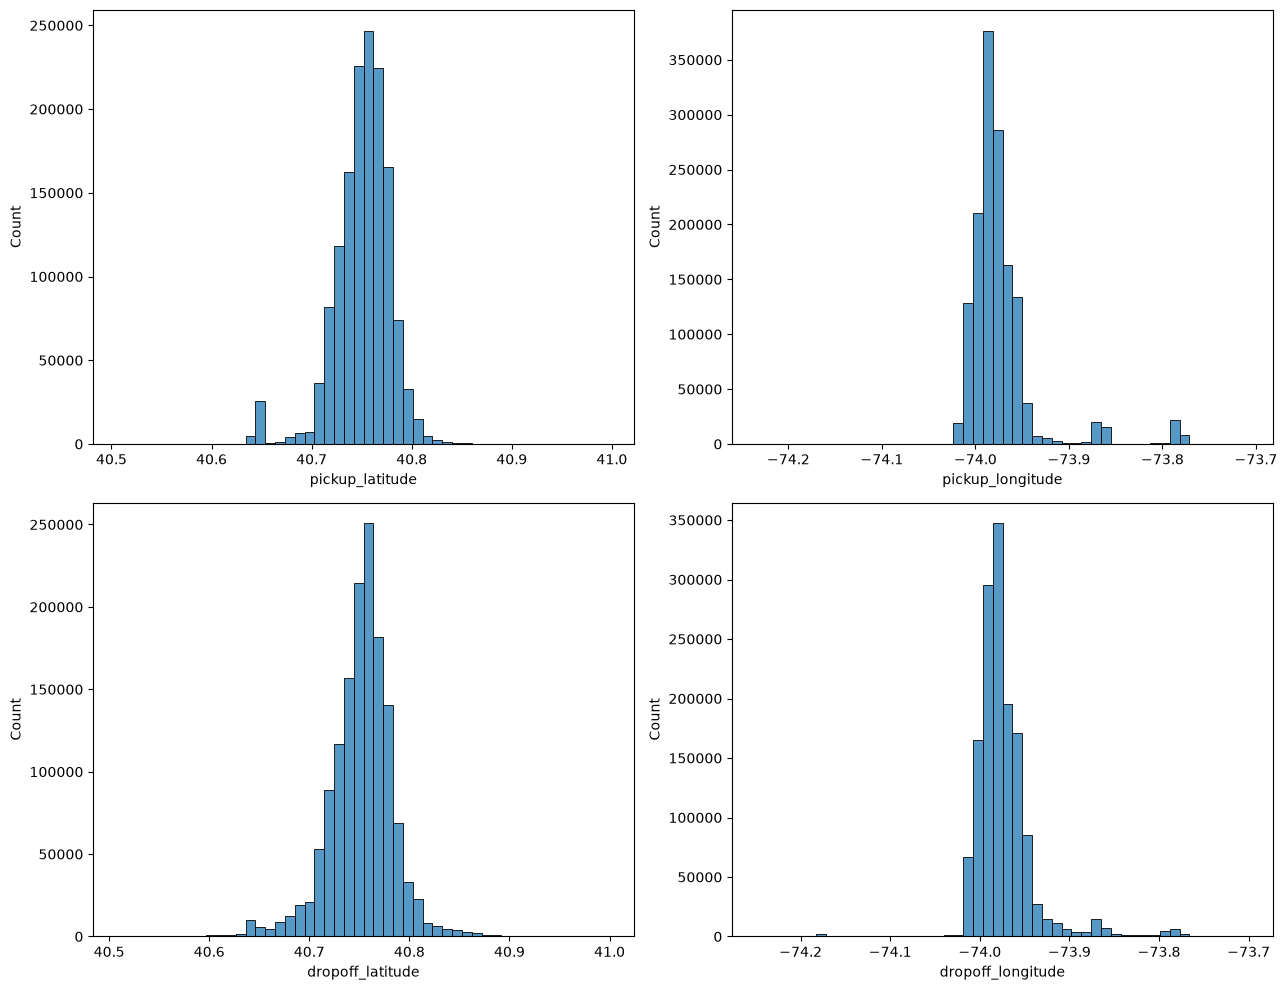

In [33]:
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(13, 10))

sns.histplot(df["pickup_latitude"], ax=axs[0, 0], bins=50)
sns.histplot(df["pickup_longitude"], ax=axs[0, 1], bins=50)

sns.histplot(df["dropoff_latitude"], ax=axs[1, 0], bins=50)
sns.histplot(df["dropoff_longitude"], ax=axs[1, 1], bins=50)

fig.tight_layout()

#### 3.4.2 - Plot of pickup and dropoff locations

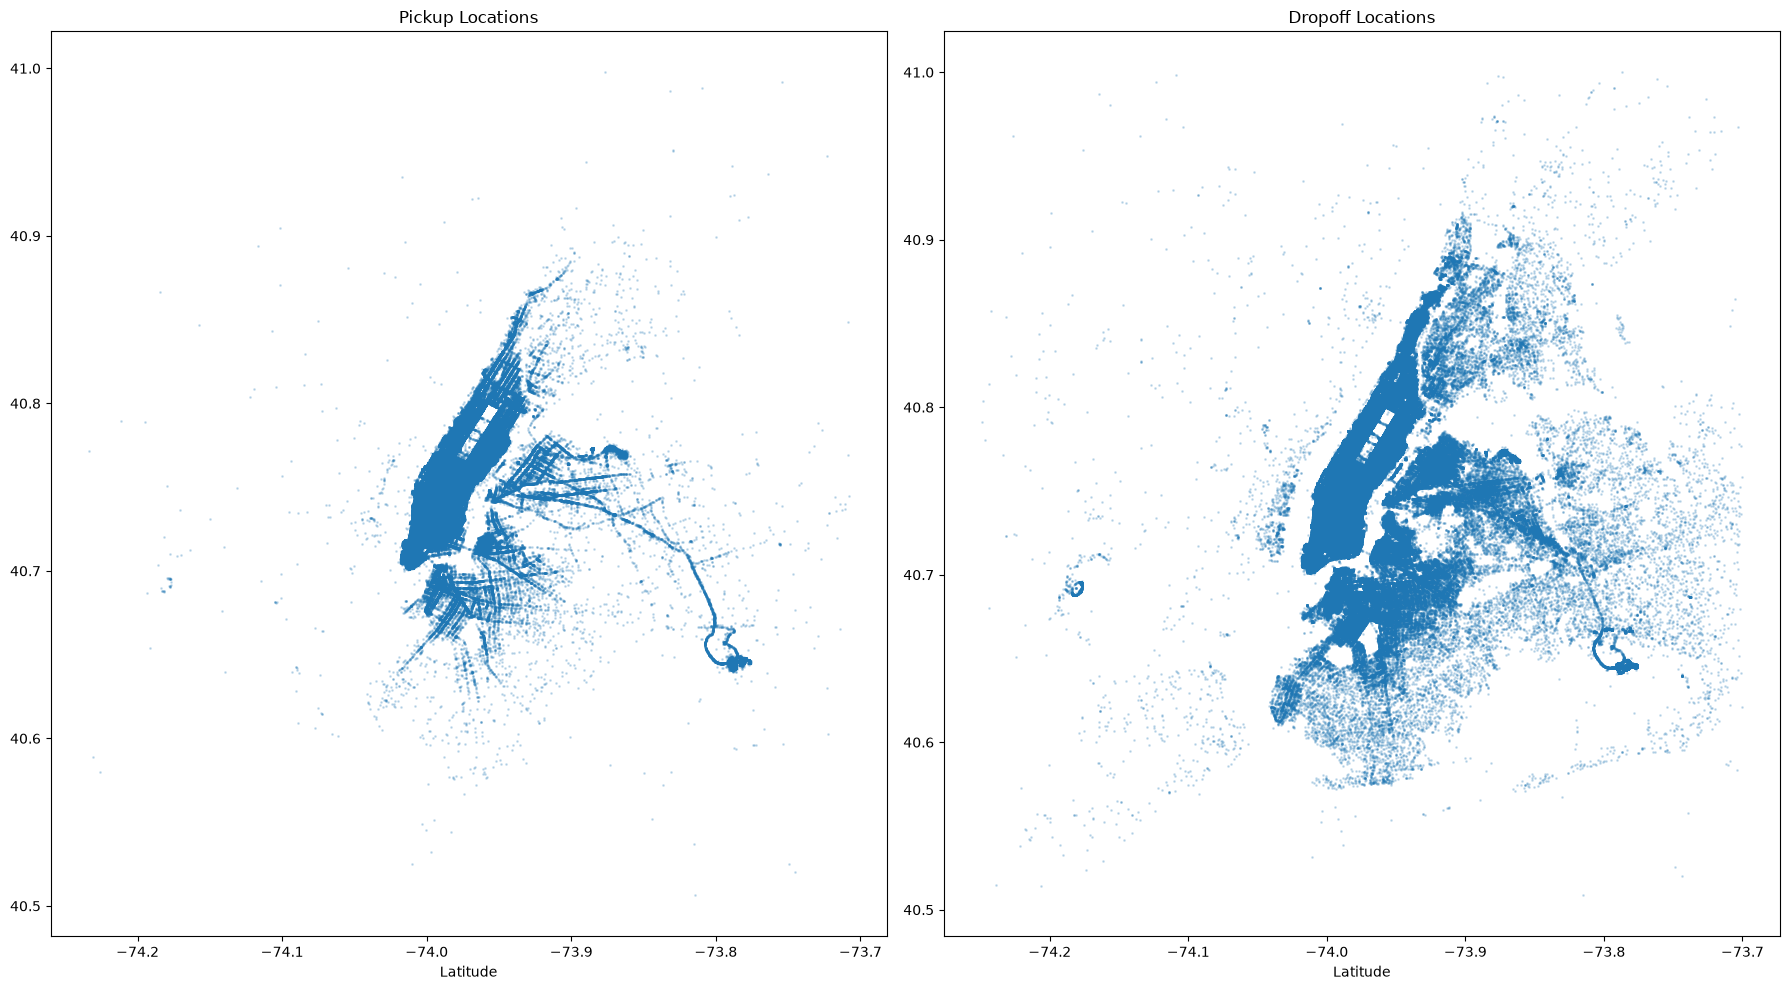

In [34]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(18, 10))

axs[0].scatter(
    df["pickup_longitude"],
    df["pickup_latitude"],
    s=1, alpha=0.2
)

axs[1].scatter(
    df["dropoff_longitude"],
    df["dropoff_latitude"],
    s=1, alpha=0.2
)

axs[0].set_xlabel("Longitude")
axs[0].set_xlabel("Latitude")
axs[0].set_title("Pickup Locations")

axs[1].set_xlabel("Longitude")
axs[1].set_xlabel("Latitude")
axs[1].set_title("Dropoff Locations")

fig.tight_layout()

#### 3.4.3 - Takeaways

- The combined plots provide a visualization of the spatial distribution of taxi activity. Both pickup and dropoff locations are heavily concentrated within Manhattan and extend into parts of Brooklyn and Queens, particularly around key areas like airports and central business districts.
- This high density in specific geographic regions suggests that location-based features (e.g. distance calculations, geohashes, spatial clustering) will be crucial for capturing variations in trip duration.
- It also confirms that our data quality check and filtering of anomalous records were effective in focusing on the trips within the relevant area.

### 3.5 - Relationships

#### 3.5.1 - Trip duration and vendor ID

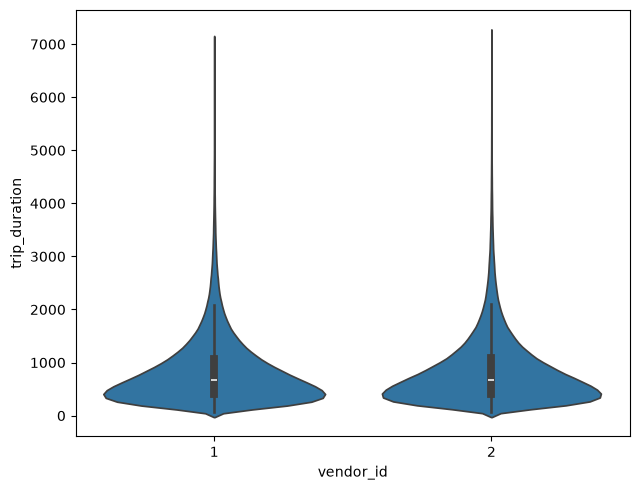

In [35]:
fig, ax = plt.subplots(figsize=(6.5, 5))

sns.violinplot(
    data=df,
    x="vendor_id",
    y="trip_duration",
    ax=ax
)

fig.tight_layout()

- The average trip durations across vendors appear broadly similar, suggesting that vendor-specific operational differences have limited influence on trip duration.
- Vendor ID may still contribute marginal predictive information but is unlikely to be a dominant feature.

#### 3.5.2 - Trip duration and passenger count

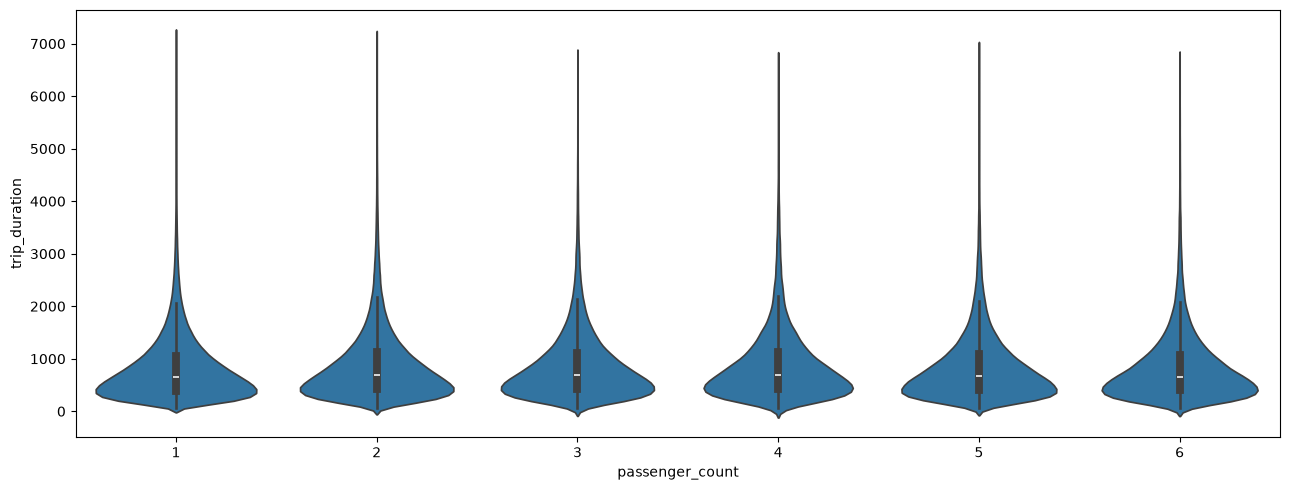

In [36]:
fig, ax = plt.subplots(figsize=(13, 5))

sns.violinplot(
    data=df,
    x="passenger_count",
    y="trip_duration",
    ax=ax
)

fig.tight_layout()

- Trip duration does not appear to vary substantially across different passenger counts.
- This suggests that `passenger_count` may have limited predictive power compared to temporal and geographic features.

#### 3.5.3 - Trip duration and pickup hour

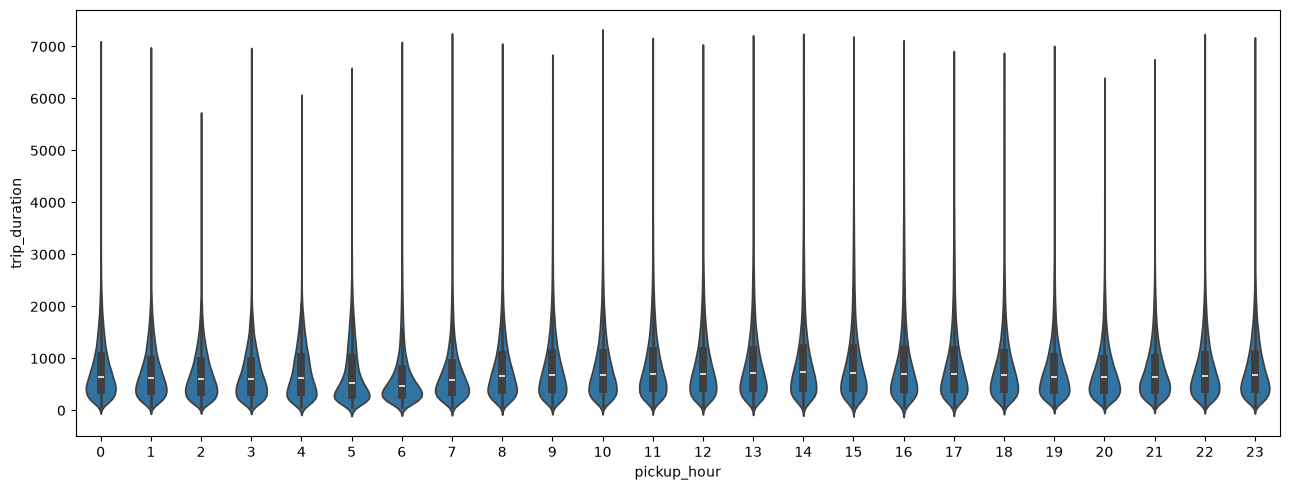

In [37]:
fig, ax = plt.subplots(figsize=(13, 5))

sns.violinplot(
    data=time_df,
    x="pickup_hour",
    y="trip_duration",
    ax=ax
)

fig.tight_layout()

- Trip duration varies noticeably throughout the day.
- Longer durations are observed during peak commuting hours, reflecting the influence of traffic congestion.
- This reinforces the importance of `pickup_hour` as a predictive feature.

#### 3.5.4 - Trip duration and day of week

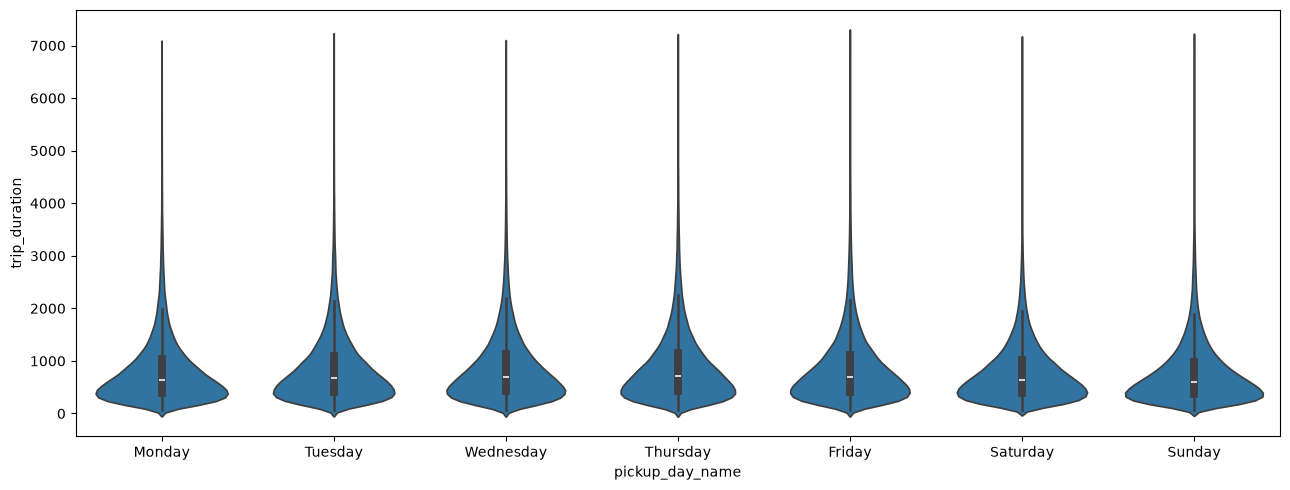

In [38]:
day_of_week = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, ax = plt.subplots(figsize=(13, 5))

sns.violinplot(
    data=time_df,
    x="pickup_day_name",
    y="trip_duration",
    order=day_of_week,
    ax=ax
)

fig.tight_layout()

- Trip durations exhibit measurable variation across the week.
- Weekday trips generally show greater duration than weekend trips, reflecting differing traffic conditions and travel behavior.

#### 3.5.5 - Trip duration and travel distance

In this part, we would use the haversine distance, which was done prior during data quality checks and filtering.

In [39]:
dist_df = time_df[["id", "trip_duration", "pickup_hour"]]
dist_df["distance"] = compute_haversine_km(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)

dist_df["distance"].describe().transpose().round(2)

count    1443728.00
mean           3.45
std            3.88
min            0.00
25%            1.25
50%            2.11
75%            3.89
max           47.77
Name: distance, dtype: float64

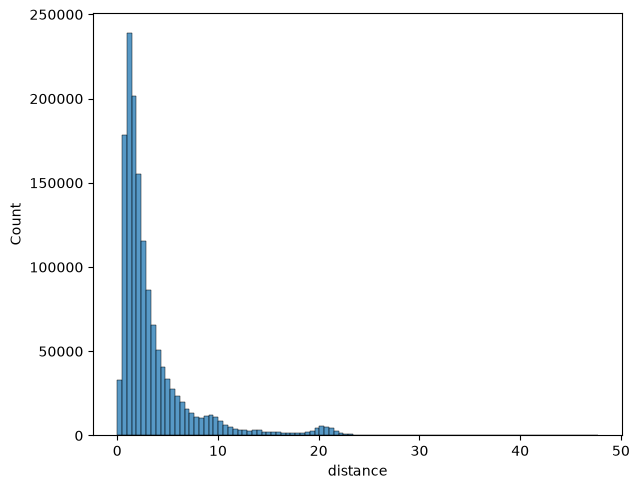

In [40]:
# Consider distribution of travelled distance

fig, ax = plt.subplots(figsize=(6.5, 5))

sns.histplot(dist_df["distance"], bins=100, ax=ax)

fig.tight_layout()

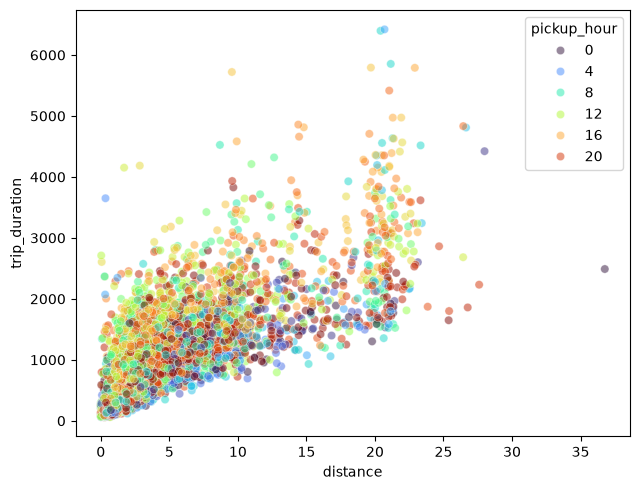

In [41]:
# Travel distance vs. trip duration

fig, ax = plt.subplots(figsize=(6.5, 5))

sns.scatterplot(
    data=dist_df.sample(n=10_000, random_state=SEED),
    x="distance",
    y="trip_duration",
    alpha=0.5,
    hue="pickup_hour",
    palette="turbo"
)

plt.tight_layout()

In [42]:
dist_df[["distance", "trip_duration"]].corr()

,distance,trip_duration
distance,1.000000,0.772471
trip_duration,0.772471,1.000000


- Travel distance exhibits a strong positive relationship with trip duration (0.77)
- As expected, longer trips generally require more travel time. However, the variability in duration increases for longer distances, indicating that factors such as traffic conditions, route choice, and congestion also influence travel time.
- The strong correlation confirms that distance is one of the most important predictors of trip duration and should play a central role in the predictive model.

### 3.6 - Summary of insights

The analysis revealed several important patterns that influence taxi trip duration in New York City.

- Trip duration exhibits a positively skewed distribution with heavy tails, indicating that while most trips are relatively short, a small number of longer trips contribute significantly to the overall variability.
- Log transformation substantially reduced skewness and produced a more symmetric target distribution, suggesting potential benefits for regression modeling.
- Temporal patterns showed clear demand fluctuations throughout the day, with trip volumes peaking during morning and evening commuting hours.
- Average trip duration increased during rush-hour periods, highlighting the influence of traffic congestion on travel time.
- Weekday trips were more frequent and longer in duration than weekend trips, indicating differing traffic and travel behavior patterns.
- Average trip duration increased gradually from January to June, suggesting the presence of seasonal effects.
- Geographically, taxi activity is concentrated within the New York City metropolitan area, with dense clusters around Manhattan and surrounding boroughs.
- The calculated Haversine distance demonstrated a strong positive relationship with trip duration making it one of the influential predictors identified.

Overall, the analysis indicates that trip duration is primarily influenced by a combination of geospatial factors (distance traveled) and temporal factors (time of day, day of week, and seasonality). These insights provide a strong foundation for feature engineering and predictive model development.

## 4 - Feature engineering

- In this section, we setup the functions for deriving the relevant additional features, which we then include within the model pipeline.
- Aside from the ones we prepared before during exploratory analysis, we will derive additional features.

In [43]:
time_df.head()

,id,trip_duration,pickup_hour,pickup_day,pickup_month,pickup_day_name,pickup_month_name,is_weekend
0,id2875421,455,17,14,3,Monday,March,False
1,id2377394,663,0,12,6,Sunday,June,True
2,id3858529,2124,11,19,1,Tuesday,January,False
3,id3504673,429,19,6,4,Wednesday,April,False
4,id2181028,435,13,26,3,Saturday,March,True


In [44]:
dist_df.head()

,id,trip_duration,pickup_hour,distance
0,id2875421,455,17,1.498521
1,id2377394,663,0,1.805507
2,id3858529,2124,11,6.385098
3,id3504673,429,19,1.485498
4,id2181028,435,13,1.188588


### 4.1 - Setup function transformers

In [45]:
def parse_dates(X: pd.DataFrame) -> pd.DataFrame:
    """Util for parsing dates in raw data."""
    X_out = X.copy()

    if "pickup_datetime" in X_out.columns:
        X_out["pickup_datetime"] = pd.to_datetime(X_out["pickup_datetime"], errors="coerce")
    if "dropoff_datetime" in X_out.columns:
        X_out["dropoff_datetime"] = pd.to_datetime(X_out["dropoff_datetime"], errors="coerce")

    return X_out


def setup_features(X: pd.DataFrame) -> pd.DataFrame:
    """Main function for feature engineering."""
    X_out = X.copy()

    # #############################
    # Encode original features
    # #############################

    X_out["store_and_fwd_flag"] = X_out["store_and_fwd_flag"].map({"N": 0, "Y": 1})

    # #############################
    # Temporal features
    # #############################

    X_out["pickup_hour"] = X_out["pickup_datetime"].dt.hour
    X_out["pickup_month"] = X_out["pickup_datetime"].dt.month
    X_out["day_of_week"] = X_out["pickup_datetime"].dt.day_of_week

    # Cyclical encoding of hour (period = 24)
    X_out["sin_hour"] = np.sin(2 * np.pi * X_out["pickup_hour"] / 24.0)
    X_out["cos_hour"] = np.cos(2 * np.pi * X_out["pickup_hour"] / 24.0)
    
    X_out["is_weekend"] = (X_out["pickup_datetime"].dt.day_of_week >= 5).astype(int)
    X_out["is_rush_hour"] = (
        (~X_out["is_weekend"].astype(bool)) & 
        (X_out["pickup_hour"].between(7, 9) | X_out["pickup_hour"].between(16, 19))
    ).astype(int)

    # #############################
    # Spatial features
    # #############################

    d_lat = X_out["dropoff_latitude"] - X_out["pickup_latitude"]
    d_lon = X_out["dropoff_longitude"] - X_out["pickup_longitude"]
    
    # Haversine distance in km
    EARTH_RADIUS = 6371.0
    phi1, phi2 = np.radians(X_out["pickup_latitude"]), np.radians(X_out["dropoff_latitude"])
    dphi = np.radians(d_lat)
    dlambda = np.radians(d_lon)
    
    a = np.sin(dphi / 2.0)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2.0)**2
    X_out["haversine_dist_km"] = 2 * EARTH_RADIUS * np.arcsin(np.sqrt(a))
    
    # Manhattan Distance (L1 approximation) in km
    # 1 deg lat ~ 111 km; 1 deg lon ~ 111 km * cos(lat)
    lat_dist = np.abs(d_lat) * 111.0
    lon_dist = np.abs(d_lon) * 111.0 * np.cos(np.radians((X_out["pickup_latitude"] + X_out["dropoff_latitude"]) / 2))
    X_out["manhattan_dist_km"] = lat_dist + lon_dist
    
    # Compass bearing / heading
    y = np.sin(dlambda) * np.cos(phi2)
    x = np.cos(phi1) * np.sin(phi2) - np.sin(phi1) * np.cos(phi2) * np.cos(dlambda)
    X_out["bearing_deg"] = (np.degrees(np.arctan2(y, x)) + 360) % 360
    
    # Airport bounding flags (JFK & LaGuardia)
    # JFK: lat [40.63, 40.66], lon [-73.80, -73.76]
    X_out["is_dropoff_airport"] = (
        X_out["dropoff_latitude"].between(40.63, 40.66) & 
        X_out["dropoff_longitude"].between(-73.80, -73.76)
    ).astype(int)
    
    return X_out

In [46]:
target = "trip_duration"

features_cols = train_df.columns.tolist()[1:-1]

feature_eng_cols = [
    "pickup_hour", 
    "pickup_month", 
    "day_of_week", 
    "sin_hour", 
    "cos_hour", 
    "is_weekend", 
    "is_rush_hour", 
    "haversine_dist_km",
    "manhattan_dist_km",
    "bearing_deg",
    "is_dropoff_airport"
]

# Columns to remove during training
cols_to_drop = [
    "trip_duration", 
    "id", 
    "dropoff_datetime", 
    "pickup_datetime",
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude"
]

In [47]:
df = setup_features(X=df)
df.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,...,pickup_month,day_of_week,sin_hour,cos_hour,is_weekend,is_rush_hour,haversine_dist_km,manhattan_dist_km,bearing_deg,is_dropoff_airport
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,0,...,3,0,-0.965926,-0.258819,0,1,1.498521,1.732417,99.970196,0
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,0,...,6,6,0.000000,1.000000,1,0,1.805507,2.426335,242.846232,0
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,0,...,1,1,0.258819,-0.965926,0,0,6.385098,8.190090,200.319835,0
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,0,...,4,2,-0.965926,0.258819,0,1,1.485498,1.658438,187.262300,0
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,0,...,3,5,-0.258819,-0.965926,1,0,1.188588,1.197355,179.473585,0


In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1443728 entries, 0 to 1443727
Data columns (total 22 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   id                  1443728 non-null  str           
 1   vendor_id           1443728 non-null  int64         
 2   pickup_datetime     1443728 non-null  datetime64[us]
 3   dropoff_datetime    1443728 non-null  datetime64[us]
 4   passenger_count     1443728 non-null  int64         
 5   pickup_longitude    1443728 non-null  float64       
 6   pickup_latitude     1443728 non-null  float64       
 7   dropoff_longitude   1443728 non-null  float64       
 8   dropoff_latitude    1443728 non-null  float64       
 9   store_and_fwd_flag  1443728 non-null  int64         
 10  trip_duration       1443728 non-null  int64         
 11  pickup_hour         1443728 non-null  int32         
 12  pickup_month        1443728 non-null  int32         
 13  day_of_week         144

### 4.2 - Correlation check

Determine if we have risk of multicollinearity within our derived numerical features.

In [49]:
columns_fe_numerical = [
    "pickup_hour", 
    "pickup_month", 
    "day_of_week", 
    "sin_hour", 
    "cos_hour", 
    "haversine_dist_km",
    "manhattan_dist_km",
    "bearing_deg"
]

corr = df[columns_fe_numerical + [target]].corr()

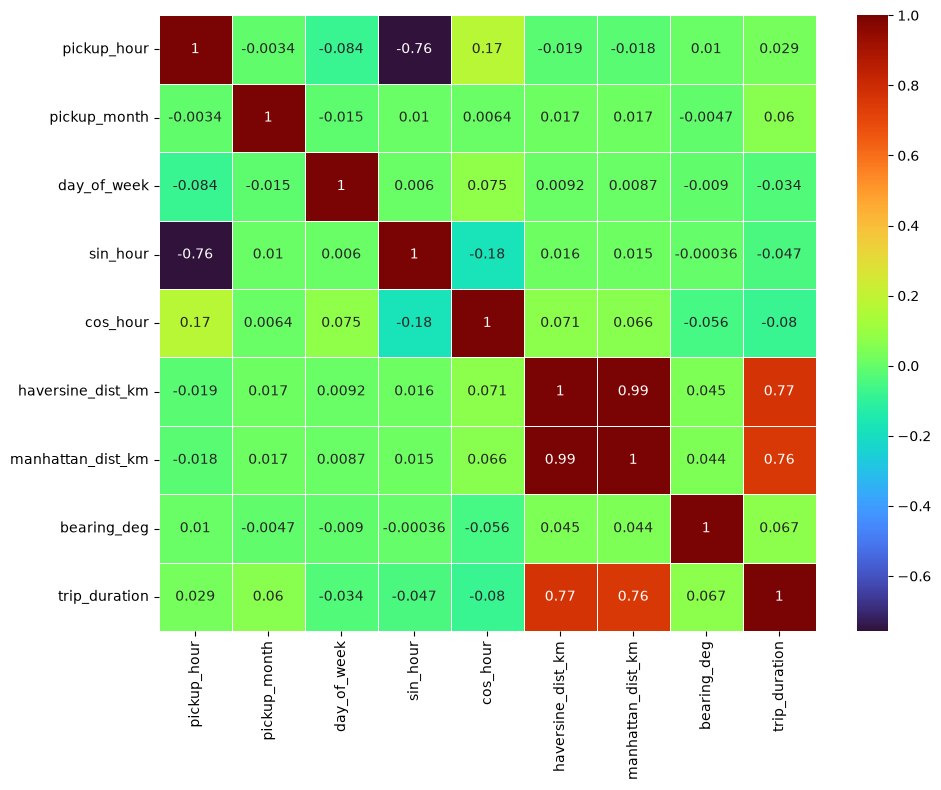

In [50]:
fig, ax = plt.subplots(figsize=(10,8))

sns.heatmap(
    corr, 
    linewidths=0.5, 
    cmap="turbo", 
    annot=True
)

fig.tight_layout()

In [51]:
corr_upper_tri = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
threshold = 0.6
high_corr = corr_upper_tri.unstack().dropna()
high_corr_pairs = high_corr[high_corr.abs() > threshold]

high_corr_pairs

sin_hour           pickup_hour         -0.757649
manhattan_dist_km  haversine_dist_km    0.994081
trip_duration      haversine_dist_km    0.772471
                   manhattan_dist_km    0.759211
dtype: float64

Remarks:

- The engineered distance-based features exhibit the strongest relationship with trip duration.
- Haversine distance achieved a strong correlation coefficient (about 0.77) with the target variable, while Manhattan distance also achieved strong correlation (about 0.76).
- A very high correlation (about 0.99) was observed between Haversine distance and Manhattan distance, indicating substantial overlap in the information captured by these variables. We also observed this between sine of hour and pickup hour.
- We retain these features for subsequent modeling, allowing regularized and tree-based models to determine their relative importance.

## 5 - Train-validation split (80/20)

- Since a test set was provided, we don't need to create a test split using the training dataset.
- Standard k-fold cross-validation relies on the assumption that samples are independently and identically distributed. However the dataset forms a time series (i.e. the records occur in a chronological order) and applying random sampling in the data leaks future macro-congestion states, roadworks, and seasonal trends back into past predictions.
- What we can do instead is arrange all the data chronologically (using the timestamp on pickup) and perform a normal split.
- For all cross-validation, only use the training split.
- To easier distinguised scaled target values (log y) from the original, we'll use `z` as prefix.

In [52]:
df = df.sort_values("pickup_datetime").reset_index(drop=True)

# Main split setup
split_idx = int(len(df) * 0.80)
train_split_df = df.iloc[:split_idx].copy()
val_split_df = df.iloc[split_idx:].copy()

# Prepare feature matrix and target vector for training set
X_full_train = train_split_df.drop(columns=cols_to_drop)
y_full_train = train_split_df[target]
z_full_train = np.log1p(train_split_df[target])

# Prepare feature matrix and target vector for validation set
X_val = val_split_df.drop(columns=cols_to_drop)
y_val = val_split_df[target]
z_val = np.log1p(val_split_df[target])

train_split_df.shape, val_split_df.shape, X_full_train.shape, y_full_train.shape, X_val.shape, y_val.shape

((1154982, 22),
 (288746, 22),
 (1154982, 14),
 (1154982,),
 (288746, 14),
 (288746,))

The training split has more than a million records. It's not practical resource-wise to use all the data at the preliminary stage of the training process, as training is slow compare to making predictions. Thus we can opt for the following approach.

- Randomly sample a smaller set from the training split, making sure it's arrange chronologically before fitting.
- We would start with 10-15% of the split, only using it for the baseline model, sanity checks, and selecting top 3 models to use based on calculated scores without finetuning.
- Once we selected the top 3 models to look at, we would increase the size of the subset from the training split (say 30-50%) and perform finetuning and cross-validation.
- We keep using the full 20% split for any single validation check.
- The chosen final model with the best parameters will then be trained using the full training split.

In [53]:
n_train_subset = int(len(train_split_df) * 0.15)
print("Training samples:", n_train_subset)

train_split_sampled_df = (
    train_split_df
    .sample(n=n_train_subset, random_state=SEED)
    .sort_values("pickup_datetime").reset_index(drop=True)
)

train_split_sampled_df.info()

Training samples: 173247
<class 'pandas.DataFrame'>
RangeIndex: 173247 entries, 0 to 173246
Data columns (total 22 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   id                  173247 non-null  str           
 1   vendor_id           173247 non-null  int64         
 2   pickup_datetime     173247 non-null  datetime64[us]
 3   dropoff_datetime    173247 non-null  datetime64[us]
 4   passenger_count     173247 non-null  int64         
 5   pickup_longitude    173247 non-null  float64       
 6   pickup_latitude     173247 non-null  float64       
 7   dropoff_longitude   173247 non-null  float64       
 8   dropoff_latitude    173247 non-null  float64       
 9   store_and_fwd_flag  173247 non-null  int64         
 10  trip_duration       173247 non-null  int64         
 11  pickup_hour         173247 non-null  int32         
 12  pickup_month        173247 non-null  int32         
 13  day_of_week    

## 6 - Establish baseline

For the baseline, let's define the following.

- `Naive global median` - The median of all `log1p(trip_duration)`.
- `Segmented lookup table` - The median log-duration stratified by (pickup_hour, distance_decile)

In [54]:
X_train = train_split_sampled_df.drop(columns=cols_to_drop)
y_train = train_split_sampled_df[target]
z_train = np.log1p(train_split_sampled_df[target])

X_train.shape, y_train.shape

((173247, 14), (173247,))

In [55]:
# Baseline 1 - Global median
global_median_log = np.median(z_train)
z_pred_val_base1 = np.full(len(val_split_df), fill_value=global_median_log)

In [56]:
# Baseline 2 - Segmented lookup table
train_split_df["dist_bin"] = pd.qcut(train_split_df["haversine_dist_km"], q=10, labels=False, duplicates="drop")
lookup = train_split_df.groupby(["pickup_hour", "dist_bin"])[target].apply(lambda s: np.median(np.log1p(s))).to_dict()

val_split_df["dist_bin"] = pd.qcut(val_split_df["haversine_dist_km"], q=10, labels=False, duplicates="drop")
z_pred_val_base2 = val_split_df.set_index(["pickup_hour", "dist_bin"]).index.map(lookup)
z_pred_val_base2 = np.nan_to_num(z_pred_val_base2, nan=global_median_log)

Note: Because we're using log scaled values, use **RMSE** to get **RMSLE**. We only use RMSLE when dealing with the unscaled values of the target.

$$ \text{RMSLE}(y, \hat{y}) = \sqrt{\frac{1}{n}\sum_{i=1}^n \left(\log(\hat{y}_i + 1) - \log(y_i + 1)\right)^2} = \sqrt{\frac{1}{n}\sum_{i=1}^n (\hat{z}_i - z_i)^2} = \text{RMSE}(z, \hat{z}) $$

In [57]:
val_rmsle_base1 = root_mean_squared_error(y_true=z_val, y_pred=z_pred_val_base1)
val_rmsle_base1

0.7427264387270065

In [58]:
val_rmsle_base2 = root_mean_squared_error(y_true=z_val, y_pred=z_pred_val_base2)
val_rmsle_base2

0.4357126658395207

## 7 - Candidate models

1. Linear-based models
    - Ridge
    - Gamma Regressor
2. Tree-based models
    - Decision Tree Regressor
    - Random Forest Regressor
    - XGBRegressor
    - LGBMRegressor

- For distance-based models such as linear models, important to apply a scaler e.g. `StandardScaler()` and use the log scale target values.

In [59]:
def get_metrics_log_scaled(z_true, z_pred, what_set="val", print_scores=True):
    y_true = np.expm1(z_true)
    y_pred = np.expm1(z_pred)
        
    rmsle = root_mean_squared_error(z_true, z_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    medae = median_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    if print_scores and what_set:
        print(f"Scores - {what_set.upper()}")
        print("RMSLE:", rmsle)
        print("RMSE:", rmse)
        print("MAE:", mae)
        print("MDAE:", medae)
        print("R2:", r2)

    return rmsle, rmse, mae, medae, r2


def get_metrics(y_true, y_pred, what_set="val", print_scores=True):
    rmsle = root_mean_squared_log_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    medae = median_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    if print_scores and what_set:
        print(f"Scores - {what_set.upper()}")
        print("RMSLE:", rmsle)
        print("RMSE:", rmse)
        print("MAE:", mae)
        print("MDAE:", medae)
        print("R2:", r2)

    return rmsle, rmse, mae, medae, r2

### 7.1 - Ridge Regression

In [60]:
model_ridge = make_pipeline(
    StandardScaler(),
    Ridge(random_state=SEED)
)

model_ridge.fit(X_train, z_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['vendor_id','passenger_count','store_and_fwd_flag',..., 'manhattan_dist_km','bearing_deg','is_dropoff_airport']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [61]:
z_pred_val = model_ridge.predict(X_val)
scores_val_base_ridge = get_metrics_log_scaled(z_val, z_pred_val)

Scores - VAL
RMSLE: 0.5280780075811753
RMSE: 1322.840115378529
MAE: 376.52579135569664
MDAE: 211.89403611575324
R2: -2.511146879441719


### 7.2 - Gamma Regressor

In [62]:
model_gr = GammaRegressor(max_iter=1000)

model_gr.fit(X_train, y_train)

,"max_iter max_iter: int, default=100The maximal number of iterations for the solver.Values must be in the range `[1, inf)`.",1000
,"alpha alpha: float, default=1Constant that multiplies the L2 penalty term and determines theregularization strength. ``alpha = 0`` is equivalent to unpenalizedGLMs. In this case, the design matrix `X` must have full column rank(no collinearities).Values of `alpha` must be in the range `[0.0, inf)`.",1.0
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the linear predictor `X @ coef_ + intercept_`.",True
,"solver solver: {'lbfgs', 'newton-cholesky'}, default='lbfgs'Algorithm to use in the optimization problem:'lbfgs' Calls scipy's L-BFGS-B optimizer.'newton-cholesky' Uses Newton-Raphson steps (in arbitrary precision arithmetic equivalent to iterated reweighted least squares) with an inner Cholesky based solver. This solver is a good choice for `n_samples` >> `n_features`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features` because it explicitly computes the Hessian matrix. .. versionadded:: 1.2",'lbfgs'
,"tol tol: float, default=1e-4Stopping criterion. For the lbfgs solver,the iteration will stop when ``max{|g_j|, j = 1, ..., d} <= tol``where ``g_j`` is the j-th component of the gradient (derivative) ofthe objective function.Values must be in the range `(0.0, inf)`.",0.0001
,"warm_start warm_start: bool, default=FalseIf set to ``True``, reuse the solution of the previous call to ``fit``as initialization for `coef_` and `intercept_`.",False
,"verbose verbose: int, default=0For the lbfgs solver set verbose to any positive number for verbosity.Values must be in the range `[0, inf)`.",0
Name,Type,Value
"coef_ coef_: array of shape (n_features,)Estimated coefficients for the linear predictor (`X @ coef_ +intercept_`) in the GLM.","ndarray[float64](14,)","[-0. , 0. , 0. ,..., 0.04, 0. ,-0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['vendor_id','passenger_count','store_and_fwd_flag',..., 'manhattan_dist_km','bearing_deg','is_dropoff_airport']"
intercept_ intercept_: floatIntercept (a.k.a. bias) added to linear predictor.,float64,6.083


In [63]:
y_pred_val = model_gr.predict(X_val)
scores_val_base_gr = get_metrics(y_val, y_pred_val)

Scores - VAL
RMSLE: 0.5681265897590543
RMSE: 878.7009198271328
MAE: 403.79410622072095
MDAE: 241.96807292309745
R2: -0.5492319554063199


### 7.3 - Decision Tree Regressor

In [64]:
model_dtr = DecisionTreeRegressor(random_state=SEED)

model_dtr.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",13
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

In [65]:
y_pred_val = model_dtr.predict(X_val)
scores_val_base_dtr = get_metrics(y_val, y_pred_val)

Scores - VAL
RMSLE: 0.5440263032788519
RMSE: 503.07485000469995
MAE: 331.39241063079663
MDAE: 214.0
R2: 0.4921920483107275


### 7.4 - Random Forest Regressor

In [66]:
model_rfr = RandomForestRegressor(random_state=SEED)

model_rfr.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",13
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [67]:
y_pred_val = model_rfr.predict(X_val)
scores_val_base_rfr = get_metrics(y_val, y_pred_val)

Scores - VAL
RMSLE: 0.40927026493995605
RMSE: 359.69616942212565
MAE: 239.97769179544184
MDAE: 165.34000000000003
R2: 0.7403992695945438


### 7.5 - XGBoost

In [68]:
model_xgbr = XGBRegressor(random_state=SEED, objective="reg:gamma")

model_xgbr.fit(X_train, y_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:gamma'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg =

In [69]:
y_pred_val = model_xgbr.predict(X_val)
scores_val_base_xgbr = get_metrics(y_val, y_pred_val)

Scores - VAL
RMSLE: 0.3900207281112671
RMSE: 348.0318298339844
MAE: 229.7750701904297
MDAE: 157.03164672851562
R2: 0.7569630742073059


### 7.6 - LightGBM

In [70]:
model_lgbmr = LGBMRegressor(random_state=SEED)

model_lgbmr.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003264 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 859
[LightGBM] [Info] Number of data points in the train set: 173247, number of used features: 14
[LightGBM] [Info] Start training from score 830.152395


,random_state,13
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001


In [71]:
y_pred_val = model_lgbmr.predict(X_val)
scores_val_base_lgbmr = get_metrics(y_val, y_pred_val)

Scores - VAL
RMSLE: 0.3931256585126774
RMSE: 347.22241767874795
MAE: 230.2400964620128
MDAE: 158.7350807240033
R2: 0.7580922412389418


### 7.7 - Summary

In [72]:
scores_val_base_dict = {
    "ridge": scores_val_base_ridge,
    "gamma": scores_val_base_gr,
    "decision_tree": scores_val_base_dtr,
    "random_forest": scores_val_base_rfr,
    "xgboost": scores_val_base_xgbr,
    "lgbm": scores_val_base_lgbmr,
}

scores_val_base_df = pd.DataFrame.from_dict(
    scores_val_base_dict, 
    orient="index", 
    columns=["rmsle", "rmse", "mae", "medae", "r2"]
)

scores_val_base_df

,rmsle,rmse,mae,medae,r2
ridge,0.528078,1322.840115,376.525791,211.894036,-2.511147
gamma,0.568127,878.700920,403.794106,241.968073,-0.549232
decision_tree,0.544026,503.074850,331.392411,214.000000,0.492192
random_forest,0.409270,359.696169,239.977692,165.340000,0.740399
xgboost,0.390021,348.031830,229.775070,157.031647,0.756963
lgbm,0.393126,347.222418,230.240096,158.735081,0.758092


- Linear models are definitely not suitable for our problem given the calculated values of R2 using the validation set.
- Consider XGBoost and LightGBM for finetuning and cross-validation.

## 8 - Hyperparameter tuning and cross-validation

In [74]:
grid_search_result_metrics = [
    "mean_test_rmsle",
    "std_test_rmsle",
    "mean_test_rmse",
    "std_test_rmse",
    "mean_test_mae",
    "std_test_mae",
    "mean_test_medae",
    "std_test_medae",
    "mean_test_r2_score",
    "std_test_r2_score",
    "rank_test_rmsle",
    "rank_test_rmse",
    "rank_test_mae",
    "rank_test_medae",
    "rank_test_r2_score"
]

summary_metrics = [
    "rmsle_mean", 
    "rmsle_std", 
    "rmse_mean", 
    "rmse_std",
    "mae_mean", 
    "mae_std",
    "medae_mean", 
    "medae_std",
    "r2_score_mean", 
    "r2_score_std",
]

def grid_search_result_summary(grid_search: GridSearchCV, model_name: str):
    print("Model:", model_name)
    print("Best params:")
    pprint(grid_search.best_params_)
    print("Best score:", grid_search.best_score_)

In [75]:
# Setup cross-validation split
tscv = TimeSeriesSplit(n_splits=5)
tscv

TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None)

Refresh split setup

In [76]:
# Main split setup
split_idx = int(len(df) * 0.80)
train_split_df = df.iloc[:split_idx].copy()
val_split_df = df.iloc[split_idx:].copy()

# Prepare feature matrix and target vector for training set
X_full_train = train_split_df.drop(columns=cols_to_drop)
y_full_train = train_split_df[target]
z_full_train = np.log1p(train_split_df[target])

# Prepare feature matrix and target vector for validation set
X_val = val_split_df.drop(columns=cols_to_drop)
y_val = val_split_df[target]
z_val = np.log1p(val_split_df[target])

train_split_df.shape, val_split_df.shape, X_full_train.shape, y_full_train.shape, X_val.shape, y_val.shape

((1154982, 22),
 (288746, 22),
 (1154982, 14),
 (1154982,),
 (288746, 14),
 (288746,))

In [77]:
# Prepare sampled subset for CV
n_cv_subset = int(len(train_split_df) * 0.30)
print("Training samples:", n_cv_subset)

train_split_sampled_df = (
    train_split_df
    .sample(n=n_cv_subset, random_state=SEED)
    .sort_values("pickup_datetime").reset_index(drop=True)
)

X_train = train_split_sampled_df.drop(columns=cols_to_drop)
y_train = train_split_sampled_df[target]
z_train = np.log1p(train_split_sampled_df[target])

X_train.shape, y_train.shape

Training samples: 346494


((346494, 14), (346494,))

### 8.1 - XGBoost

In [78]:
# Consider the best number of estimators

model = XGBRegressor(random_state=SEED, objective="reg:gamma")

params_xgbr = {
    "n_estimators": [300, 400, 500]
}

scoring = {
    "rmsle": "neg_root_mean_squared_log_error",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "medae": "neg_median_absolute_error",
    "r2_score": "r2"
}

result_cv_xgbr = GridSearchCV(
    estimator=model,
    param_grid=params_xgbr,
    cv=tscv,
    scoring=scoring,
    refit="rmsle",
    verbose=2
)

result_cv_xgbr.fit(X_train, y_train)

Fitting 5 folds for each of 3 candidates, totalling 15 fits
[CV] END ...................................n_estimators=300; total time=   0.3s
[CV] END ...................................n_estimators=300; total time=   0.4s
[CV] END ...................................n_estimators=300; total time=   0.5s
[CV] END ...................................n_estimators=300; total time=   0.6s
[CV] END ...................................n_estimators=300; total time=   0.8s
[CV] END ...................................n_estimators=400; total time=   0.4s
[CV] END ...................................n_estimators=400; total time=   0.5s
[CV] END ...................................n_estimators=400; total time=   0.7s
[CV] END ...................................n_estimators=400; total time=   0.8s
[CV] END ...................................n_estimators=400; total time=   1.1s
[CV] END ...................................n_estimators=500; total time=   0.5s
[CV] END ...................................n_est

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_estimators': [300, 400, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'mae': 'neg_mean_absolute_error', 'medae': 'neg_median_absolute_error', 'r2_score': 'r2', 'rmse': 'neg_root_mean_squared_error', ...}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'rmsle'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;-

In [79]:
grid_search_result_summary(result_cv_xgbr, "xgboost")

Model: xgboost
Best params:
{'n_estimators': 300}
Best score: -0.37286160588264466


In [80]:
results_cols = [
    "param_n_estimators"
] + grid_search_result_metrics

cv_results_df = pd.DataFrame(result_cv_xgbr.cv_results_)[results_cols]
cv_results_df.sort_values(by="rank_test_rmsle").head(5)

,param_n_estimators,mean_test_rmsle,std_test_rmsle,mean_test_rmse,std_test_rmse,mean_test_mae,std_test_mae,mean_test_medae,std_test_medae,mean_test_r2_score,std_test_r2_score,rank_test_rmsle,rank_test_rmse,rank_test_mae,rank_test_medae,rank_test_r2_score
0,300,-0.372862,0.006202,-317.608588,19.232515,-205.864438,11.087785,-138.304645,6.486274,0.751451,0.016486,1,1,1,1,1
1,400,-0.374996,0.006341,-318.978656,18.922638,-206.715781,10.800637,-138.585510,6.390341,0.749206,0.017632,2,2,2,2,2
2,500,-0.376811,0.006305,-320.091449,18.701671,-207.451215,10.561423,-138.857193,5.865715,0.747390,0.018347,3,3,3,3,3


In [81]:
# Consider other parameters

model = XGBRegressor(n_estimators=300, random_state=SEED, objective="reg:gamma")

params_xgbr = {
    "max_depth": [2, 4, 6, 8, 10, 12],
    "min_child_weight": [20, 40, 100, 200],
    "learning_rate": [0.01, 0.03, 0.05]
}

scoring = {
    "rmsle": "neg_root_mean_squared_log_error",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "medae": "neg_median_absolute_error",
    "r2_score": "r2"
}

result_cv_xgbr = GridSearchCV(
    estimator=model,
    param_grid=params_xgbr,
    cv=tscv,
    scoring=scoring,
    refit="rmsle",
    verbose=2,
    n_jobs=-1
)

result_cv_xgbr.fit(X_train, y_train)

Fitting 5 folds for each of 72 candidates, totalling 360 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.01, 0.03, ...], 'max_depth': [2, 4, ...], 'min_child_weight': [20, 40, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'mae': 'neg_mean_absolute_error', 'medae': 'neg_median_absolute_error', 'r2_score': 'r2', 'rmse': 'neg_root_mean_squared_error', ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'rmsle'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that ca

In [82]:
grid_search_result_summary(result_cv_xgbr, "xgboost")

Model: xgboost
Best params:
{'learning_rate': 0.03, 'max_depth': 8, 'min_child_weight': 20}
Best score: -0.36518838405609133


In [83]:
results_cols = [
    "param_max_depth",
    "param_min_child_weight",
    "param_learning_rate",
] + grid_search_result_metrics

cv_results_df = pd.DataFrame(result_cv_xgbr.cv_results_)[results_cols]
cv_results_df.sort_values(by="rank_test_rmsle").head(5)

,param_max_depth,param_min_child_weight,param_learning_rate,mean_test_rmsle,std_test_rmsle,mean_test_rmse,std_test_rmse,mean_test_mae,std_test_mae,mean_test_medae,std_test_medae,mean_test_r2_score,std_test_r2_score,rank_test_rmsle,rank_test_rmse,rank_test_mae,rank_test_medae,rank_test_r2_score
36,8,20,0.03,-0.365188,0.006325,-314.438873,20.478966,-202.991965,11.632701,-135.656927,6.416042,0.756702,0.012748,1,15,4,4,14
37,8,40,0.03,-0.365402,0.006312,-314.264563,20.617542,-203.052356,11.652987,-135.827881,6.456949,0.756984,0.012777,2,12,6,7,12
56,6,20,0.05,-0.365433,0.006468,-314.654993,20.827318,-203.588235,11.974113,-136.458859,6.744904,0.756428,0.012168,3,17,21,25,17
57,6,40,0.05,-0.365447,0.006363,-314.572693,20.901014,-203.553793,12.006689,-136.494580,6.878452,0.756559,0.012256,4,16,20,26,16
60,8,20,0.05,-0.365466,0.006250,-314.048657,19.908119,-202.881973,11.340442,-135.651691,6.436983,0.757220,0.013432,5,10,1,3,10


In [84]:
cv_results_df.sort_values(by="rank_test_r2_score").head(5)

,param_max_depth,param_min_child_weight,param_learning_rate,mean_test_rmsle,std_test_rmsle,mean_test_rmse,std_test_rmse,mean_test_mae,std_test_mae,mean_test_medae,std_test_medae,mean_test_r2_score,std_test_r2_score,rank_test_rmsle,rank_test_rmse,rank_test_mae,rank_test_medae,rank_test_r2_score
62,8,100,0.05,-0.365622,0.006080,-313.564215,20.482046,-202.985132,11.622304,-136.123669,6.410532,0.758053,0.012815,8,2,3,17,1
67,10,200,0.05,-0.366143,0.006112,-313.551569,20.162955,-203.030597,11.512073,-136.165012,6.548497,0.758035,0.012983,14,1,5,19,2
63,8,200,0.05,-0.366016,0.006106,-313.694855,20.383390,-203.152249,11.566774,-136.424915,6.477756,0.757842,0.012814,11,4,11,24,3
71,12,200,0.05,-0.366463,0.006031,-313.672955,20.186247,-203.113007,11.473147,-135.864569,6.367185,0.757840,0.013161,23,3,9,8,4
61,8,40,0.05,-0.365548,0.006061,-313.790381,19.989742,-202.885825,11.373416,-135.793149,6.444606,0.757634,0.013288,6,5,2,6,5


In [85]:
scores_xgbc = cv_results_df.iloc[result_cv_xgbr.best_index_][3:-5].abs().to_dict()

scores_cv_df = pd.DataFrame([scores_xgbc.values()], columns=summary_metrics, index=["xgboost"])
scores_cv_df

,rmsle_mean,rmsle_std,rmse_mean,rmse_std,mae_mean,mae_std,medae_mean,medae_std,r2_score_mean,r2_score_std
xgboost,0.365188,0.006325,314.438873,20.478966,202.991965,11.632701,135.656927,6.416042,0.756702,0.012748


### 8.2 - LightGBM

In [86]:
# Consider the best number of estimators

model = LGBMRegressor(random_state=SEED)

params_lgbm = {
    "n_estimators": [300, 400, 500]
}

scoring = {
    "rmsle": "neg_root_mean_squared_log_error",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "medae": "neg_median_absolute_error",
    "r2_score": "r2"
}

result_cv_lgbm = GridSearchCV(
    estimator=model,
    param_grid=params_lgbm,
    cv=tscv,
    scoring=scoring,
    refit="rmsle",
    verbose=2
)

result_cv_lgbm.fit(X_train, y_train)

Fitting 5 folds for each of 3 candidates, totalling 15 fits
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001278 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 853
[LightGBM] [Info] Number of data points in the train set: 57749, number of used features: 13
[LightGBM] [Info] Start training from score 784.941003
[CV] END ...................................n_estimators=300; total time=   0.3s
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002105 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 856
[LightGBM] [Info] Number of data points in the train set: 115498, number of used features: 14
[LightGBM] [Info] Start training from score 790.372734
[CV] END ...................................

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LGBMRegressor(random_state=13)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_estimators': [300, 400, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'mae': 'neg_mean_absolute_error', 'medae': 'neg_median_absolute_error', 'r2_score': 'r2', 'rmse': 'neg_root_mean_squared_error', ...}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'rmsle'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >

In [87]:
grid_search_result_summary(result_cv_lgbm, "lightgbm")

Model: lightgbm
Best params:
{'n_estimators': 300}
Best score: -0.368923658248227


In [88]:
results_cols = [
    "param_n_estimators"
] + grid_search_result_metrics

cv_results_df = pd.DataFrame(result_cv_lgbm.cv_results_)[results_cols]
cv_results_df.sort_values(by="rank_test_rmsle").head(5)

,param_n_estimators,mean_test_rmsle,std_test_rmsle,mean_test_rmse,std_test_rmse,mean_test_mae,std_test_mae,mean_test_medae,std_test_medae,mean_test_r2_score,std_test_r2_score,rank_test_rmsle,rank_test_rmse,rank_test_mae,rank_test_medae,rank_test_r2_score
0,300,-0.368924,0.006007,-313.665383,19.742253,-203.783459,11.464957,-137.614088,6.953921,0.757748,0.014391,1,1,1,3,1
1,400,-0.369057,0.005692,-313.894654,19.494826,-203.815880,11.286008,-137.406148,6.737724,0.757342,0.014903,2,2,2,1,2
2,500,-0.369279,0.005483,-314.185461,19.345887,-203.934008,11.177615,-137.452716,6.610097,0.756864,0.015161,3,3,3,2,3


In [89]:
# Consider other parameters

model = LGBMRegressor(n_estimators=300, random_state=SEED)

params_lgbm = {
    "num_leaves": [31, 62, 93, 124, 255],
    "min_child_samples": [20, 50, 100, 200, 500],
    "learning_rate": [0.01, 0.03, 0.05]
}

scoring = {
    "rmsle": "neg_root_mean_squared_log_error",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "medae": "neg_median_absolute_error",
    "r2_score": "r2"
}

result_cv_lgbm = GridSearchCV(
    estimator=model,
    param_grid=params_lgbm,
    cv=tscv,
    scoring=scoring,
    refit="rmsle",
    verbose=1,
    n_jobs=-1
)

result_cv_lgbm.fit(X_train, y_train)

Fitting 5 folds for each of 75 candidates, totalling 375 fits
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006940 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 859
[LightGBM] [Info] Number of data points in the train set: 346494, number of used features: 14
[LightGBM] [Info] Start training from score 828.066166


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LGBMRegressor...ndom_state=13)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.01, 0.03, ...], 'min_child_samples': [20, 50, ...], 'num_leaves': [31, 62, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'mae': 'neg_mean_absolute_error', 'medae': 'neg_median_absolute_error', 'r2_score': 'r2', 'rmse': 'neg_root_mean_squared_error', ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'rmsle'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that 

In [90]:
grid_search_result_summary(result_cv_lgbm, "lightgbm")

Model: lightgbm
Best params:
{'learning_rate': 0.05, 'min_child_samples': 200, 'num_leaves': 62}
Best score: -0.36757407139047527


In [91]:
results_cols = [
    "param_num_leaves",
    "param_min_child_samples",
    "param_learning_rate",
] + grid_search_result_metrics

cv_results_df = pd.DataFrame(result_cv_lgbm.cv_results_)[results_cols]
cv_results_df.sort_values(by="rank_test_rmsle").head(5)

,param_num_leaves,param_min_child_samples,param_learning_rate,mean_test_rmsle,std_test_rmsle,mean_test_rmse,std_test_rmse,mean_test_mae,std_test_mae,mean_test_medae,std_test_medae,mean_test_r2_score,std_test_r2_score,rank_test_rmsle,rank_test_rmse,rank_test_mae,rank_test_medae,rank_test_r2_score
66,62,200,0.05,-0.367574,0.006010,-312.800618,19.998068,-203.240311,11.539762,-137.144984,6.753352,0.759160,0.013361,1,5,5,8,5
62,93,100,0.05,-0.367667,0.005856,-312.672091,19.724875,-203.186371,11.395963,-136.946706,6.651449,0.759294,0.014109,2,1,1,2,2
61,62,100,0.05,-0.367699,0.006007,-312.706154,20.100926,-203.245176,11.613845,-137.284905,6.694446,0.759306,0.013543,3,2,6,18,1
38,124,100,0.03,-0.367714,0.006006,-312.766455,19.875814,-203.188345,11.470088,-136.967824,6.809009,0.759188,0.013634,4,4,2,4,4
67,93,200,0.05,-0.367738,0.005733,-312.811363,19.728847,-203.273292,11.314129,-137.043436,6.546432,0.759101,0.013708,5,6,8,5,6


In [92]:
scores_lgbm = cv_results_df.iloc[result_cv_lgbm.best_index_][3:-5].abs().to_dict()

scores_cv_df = pd.concat([scores_cv_df, pd.DataFrame([scores_lgbm.values()], columns=summary_metrics, index=["lightgbm"])])
scores_cv_df

,rmsle_mean,rmsle_std,rmse_mean,rmse_std,mae_mean,mae_std,medae_mean,medae_std,r2_score_mean,r2_score_std
xgboost,0.365188,0.006325,314.438873,20.478966,202.991965,11.632701,135.656927,6.416042,0.756702,0.012748
lightgbm,0.367574,0.006010,312.800618,19.998068,203.240311,11.539762,137.144984,6.753352,0.759160,0.013361


- Based on the resulting scores, both models are performing almost identically. Hence the choice would depend on other factors such as compute speed and resource use.
- In this case, as the competition priorities RMSLE, we can opt for choosing **XGBoost** here as the final model.
- Note that we could try out exploring other parameters to finetune here.

## 9 - Feature importance

Using the best model, let's check feature importance and then permutation importance. By doing so would give us an idea on what features make the most impact in the predictions of the model.

In [93]:
model_pick = result_cv_xgbr.best_estimator_
model_pick

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:gamma'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg =

In [94]:
importances = pd.Series(
    model_pick.feature_importances_, 
    index=model_pick.feature_names_in_
)

importances.sort_values(ascending=False).head(10)

haversine_dist_km     0.723552
cos_hour              0.085213
pickup_hour           0.033186
day_of_week           0.031731
sin_hour              0.028973
bearing_deg           0.025878
is_dropoff_airport    0.019285
manhattan_dist_km     0.011839
is_rush_hour          0.011203
vendor_id             0.011010
dtype: float32

For the permutation importance, we set it up using the validation set.

In [96]:
scoring = {
    "rmsle": "neg_root_mean_squared_log_error",
    "r2_score": "r2"
}

result_perm_importance = permutation_importance(
    model_pick, 
    X_val,
    y_val, 
    scoring=scoring,
    random_state=SEED
)

In [97]:
df_perm_importances_rmsle = pd.DataFrame(
    {"importance": result_perm_importance["rmsle"].importances_mean, "std": result_perm_importance["rmsle"].importances_std}, 
    index=model_pick.feature_names_in_
).sort_values(by="importance", ascending=False)

df_perm_importances_r2 = pd.DataFrame(
    {"importance": result_perm_importance["r2_score"].importances_mean, "std": result_perm_importance["r2_score"].importances_std}, 
    index=model_pick.feature_names_in_
).sort_values(by="importance", ascending=False)

In [98]:
df_perm_importances_rmsle.head()

,importance,std
haversine_dist_km,0.552449,0.000862
bearing_deg,0.054694,0.000231
cos_hour,0.039972,0.000342
day_of_week,0.034609,0.000129
pickup_hour,0.020466,0.000219


In [99]:
df_perm_importances_r2.head()

,importance,std
haversine_dist_km,1.370833,0.002489
cos_hour,0.095096,0.000991
bearing_deg,0.066204,0.000777
day_of_week,0.062112,0.000437
pickup_hour,0.048047,0.000435


- As shown in the permutation importance, the harvensine distance causes the largest drop in out-of-fold scores.
- The result also shown to be consistent from the feature importance.
- This means the distance of the trip is the primary driver of predicting trip duration across the model.

## 10 - Final model

In [127]:
def parse_dates(X: pd.DataFrame) -> pd.DataFrame:
    """Util for parsing dates in raw data."""
    X_out = X.copy()

    if "pickup_datetime" in X_out.columns:
        X_out["pickup_datetime"] = pd.to_datetime(X_out["pickup_datetime"], errors="coerce")
    if "dropoff_datetime" in X_out.columns:
        X_out["dropoff_datetime"] = pd.to_datetime(X_out["dropoff_datetime"], errors="coerce")

    return X_out


def setup_features(X: pd.DataFrame) -> pd.DataFrame:
    """Main function for feature engineering."""
    X_out = X.copy()

    # #############################
    # Encode original features
    # #############################

    X_out["store_and_fwd_flag"] = X_out["store_and_fwd_flag"].map({"N": 0, "Y": 1})

    # #############################
    # Temporal features
    # #############################

    X_out["pickup_hour"] = X_out["pickup_datetime"].dt.hour
    X_out["pickup_month"] = X_out["pickup_datetime"].dt.month
    X_out["day_of_week"] = X_out["pickup_datetime"].dt.day_of_week

    # Cyclical encoding of hour (period = 24)
    X_out["sin_hour"] = np.sin(2 * np.pi * X_out["pickup_hour"] / 24.0)
    X_out["cos_hour"] = np.cos(2 * np.pi * X_out["pickup_hour"] / 24.0)
    
    X_out["is_weekend"] = (X_out["pickup_datetime"].dt.day_of_week >= 5).astype(int)
    X_out["is_rush_hour"] = (
        (~X_out["is_weekend"].astype(bool)) & 
        (X_out["pickup_hour"].between(7, 9) | X_out["pickup_hour"].between(16, 19))
    ).astype(int)

    # #############################
    # Spatial features
    # #############################

    d_lat = X_out["dropoff_latitude"] - X_out["pickup_latitude"]
    d_lon = X_out["dropoff_longitude"] - X_out["pickup_longitude"]
    
    # Haversine distance in km
    EARTH_RADIUS = 6371.0
    phi1, phi2 = np.radians(X_out["pickup_latitude"]), np.radians(X_out["dropoff_latitude"])
    dphi = np.radians(d_lat)
    dlambda = np.radians(d_lon)
    
    a = np.sin(dphi / 2.0)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2.0)**2
    X_out["haversine_dist_km"] = 2 * EARTH_RADIUS * np.arcsin(np.sqrt(a))
    
    # Manhattan Distance (L1 approximation) in km
    # 1 deg lat ~ 111 km; 1 deg lon ~ 111 km * cos(lat)
    lat_dist = np.abs(d_lat) * 111.0
    lon_dist = np.abs(d_lon) * 111.0 * np.cos(np.radians((X_out["pickup_latitude"] + X_out["dropoff_latitude"]) / 2))
    X_out["manhattan_dist_km"] = lat_dist + lon_dist
    
    # Compass bearing / heading
    y = np.sin(dlambda) * np.cos(phi2)
    x = np.cos(phi1) * np.sin(phi2) - np.sin(phi1) * np.cos(phi2) * np.cos(dlambda)
    X_out["bearing_deg"] = (np.degrees(np.arctan2(y, x)) + 360) % 360
    
    # Airport bounding flags (JFK & LaGuardia)
    # JFK: lat [40.63, 40.66], lon [-73.80, -73.76]
    X_out["is_dropoff_airport"] = (
        X_out["dropoff_latitude"].between(40.63, 40.66) & 
        X_out["dropoff_longitude"].between(-73.80, -73.76)
    ).astype(int)

    # #############################
    # Cleanup features
    # #############################

    cols_to_drop = [
        "id",
        "dropoff_datetime",
        "pickup_datetime",
        "pickup_longitude",
        "pickup_latitude",
        "dropoff_longitude",
        "dropoff_latitude"
    ]

    for c in cols_to_drop:
        if c in X_out.columns:
            X_out = X_out.drop(columns=c)
    
    return X_out

In [128]:
model_pipeline = Pipeline(steps=[
    ("parse_dates", FunctionTransformer(parse_dates)),
    ("setup_fe", FunctionTransformer(setup_features)),
    ("model", XGBRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=8,
        min_child_weight=20,
        random_state=SEED,
        objective="reg:gamma"
    ))
])
model_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('parse_dates', ...), ('setup_fe', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function par...0023DCD187270>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDict

In [129]:
X_full_train = train_df.drop(columns=target)
y_full_train = train_df[target]

X_full_train.shape, y_full_train.shape

((1458644, 10), (1458644,))

In [130]:
model_pipeline.fit(X_full_train, y_full_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('parse_dates', ...), ('setup_fe', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['id','vendor_id','pickup_datetime',...,'dropoff_longitude', 'dropoff_latitude','store_and_fwd_flag']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function par...0023DCD187270>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False


In [131]:
model_pipeline[:-1].transform(test_df).info()

<class 'pandas.DataFrame'>
RangeIndex: 625134 entries, 0 to 625133
Data columns (total 14 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   vendor_id           625134 non-null  int64  
 1   passenger_count     625134 non-null  int64  
 2   store_and_fwd_flag  625134 non-null  int64  
 3   pickup_hour         625134 non-null  int32  
 4   pickup_month        625134 non-null  int32  
 5   day_of_week         625134 non-null  int32  
 6   sin_hour            625134 non-null  float64
 7   cos_hour            625134 non-null  float64
 8   is_weekend          625134 non-null  int64  
 9   is_rush_hour        625134 non-null  int64  
 10  haversine_dist_km   625134 non-null  float64
 11  manhattan_dist_km   625134 non-null  float64
 12  bearing_deg         625134 non-null  float64
 13  is_dropoff_airport  625134 non-null  int64  
dtypes: float64(5), int32(3), int64(6)
memory usage: 59.6 MB


In [132]:
y_pred_test = model_pipeline.predict(test_df)
y_pred_test.shape

(625134,)

## 11 - Kaggle submission

In [135]:
submission_df = pd.DataFrame({
    "id": test_df["id"],
    "trip_duration": y_pred_test
})

In [136]:
assert len(submission) == len(test_df), "Row count mismatch between test and submission!"
assert not submission['trip_duration'].isnull().any(), "NaN detected in predictions!"
assert not np.isinf(submission['trip_duration']).any(), "Infinite value detected in predictions!"
assert (submission['trip_duration'] >= 0).all(), "Negative trip durations detected!"

In [137]:
submission_df.to_csv("asb_cs5b_submission.csv", index=False)